# 05 — Real Field GP Simulation (Jenny Cheng's Vernal Pool Site)

Applies the validated GP + informative-sampling + GRG path-planning pipeline
to field data from Jenny Cheng's vernal pool watershed monitoring site at
University of Toronto Scarborough campus.  Three soil-moisture / temperature
campaigns (June 10–19, June 29, July 3 2026) across 30 GCP locations.

Sections:
1. Data loading — three xlsx campaigns + shapefiles
2. Data provenance summary + open questions for Jenny
3. UTM domain + site visualisation
4. Routing graph (pool-obstacle-pruned)
5. GP fitting with learned hyperparameters (June campaign)
6. LOO-CV calibration
7. GP posterior map
8. K_all for GRG + budget calibration
9. GRG tractability check
10. GRG sweep (depth=3, all budgets)
11. Nearest-neighbour baseline
12. Results comparison + visualisation
13. Summary

In [1]:
# -------------------------------------------
# 0) Imports and project wiring
# -------------------------------------------
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import geopandas as gpd
from shapely.geometry import LineString
from shapely.ops import unary_union
from shapely.affinity import translate as shp_translate
import networkx as nx
import torch
import gpytorch

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)
import importlib; importlib.invalidate_caches()

from src.planners import (
    travel_time_matrix, gp_mutual_information, grg_plan,
    nearest_neighbor_tour_fixed_end,
)

print("All imports OK")
print("project_root:", project_root)

All imports OK
project_root: C:\Users\lukhs\Documents\Coding\Internships\ARCO\GP-Planning


## 1) Configuration

In [2]:
# -------------------------------------------
# 1) Config
# -------------------------------------------
REFS_DIR   = os.path.join(project_root, "refs")
UTM_CRS    = "EPSG:32617"   # WGS84 UTM Zone 17N

GCP_SHP    = os.path.join(REFS_DIR, "VPshapefiles", "Vernalpoolgcps20260617_XYTableToPoint.shp")
POOL_BUF   = os.path.join(REFS_DIR, "VPshapefiles", "VPBoundary_PairwiseBuffer.shp")
AREA_BND   = os.path.join(REFS_DIR, "VPshapefiles", "AreaBoundary.shp")
XLSX_JUNE  = os.path.join(REFS_DIR, "VP Soil Data.xlsx")
XLSX_JUN29 = os.path.join(REFS_DIR, "VP Soil Data June 29, 2026.xlsx")
XLSX_JUL3  = os.path.join(REFS_DIR, "VP Soil Data July 3, 2026.xlsx")

TRAVEL_SPEED     = 1.0     # m/s — nominal WELL-E speed
PRIMARY_VARIABLE = "wc"    # "wc" = water content, "temp" = temperature
DEPTH            = 4    # depth d: k_max = 2^d-1 intermediate waypoints
                          # d=3→7, d=4→15, d=5→31; NN reaches 18 at τ=157s
N_TAU_SPLITS     = 2
GP_TRAIN_ITERS   = 320
GP_LR            = 0.02
BASE_NODE        = 0       # node index for VERNAL_BASE in routing graph

print("Config OK")
print(f"  travel_speed   = {TRAVEL_SPEED} m/s")
print(f"  depth          = {DEPTH},  n_tau_splits = {N_TAU_SPLITS}")
print(f"  primary var    = {PRIMARY_VARIABLE}")
print(f"  GP train iters = {GP_TRAIN_ITERS}")

Config OK
  travel_speed   = 1.0 m/s
  depth          = 4,  n_tau_splits = 2
  primary var    = wc
  GP train iters = 320


## 2) Load Xlsx Campaigns

Three campaigns in wide-format xlsx files.  Each has a per-GCP summary table:
- **VP Soil Data.xlsx** (June 10–19): rows 86–115, cols 4 (GCP int), 6 (AvgWC), 7 (AvgTemp).
  Col 5 is a Date column, so WC is col 6 and Temp is col 7.
- **June 29 / July 3** xlsx: rows 38–67, cols 4 (GCP int), 5 (AvgWC), 6 (AvgTemp).

The VP18 typo ("V18") in the June 29 xlsx cell M15 is in a raw-measurement block,
not the summary table — the summary table is correct.

In [3]:
# -------------------------------------------
# 2) Load xlsx summary tables
# -------------------------------------------
def _load_june(path):
    df = pd.read_excel(path, header=None)
    # Summary at rows 86-115: col 4 = GCP int, col 6 = AvgWC, col 7 = AvgTemp
    s = df.iloc[86:116, [4, 6, 7]].copy()
    s.columns = ["GCP", "AvgWC", "AvgTemp"]
    s["GCP"] = s["GCP"].astype(int)
    return s.sort_values("GCP").reset_index(drop=True)

def _load_later(path):
    df = pd.read_excel(path, header=None)
    # Summary at rows 38-67: col 4 = GCP int, col 5 = AvgWC, col 6 = AvgTemp
    s = df.iloc[38:68, [4, 5, 6]].copy()
    s.columns = ["GCP", "AvgWC", "AvgTemp"]
    s["GCP"] = s["GCP"].astype(int)
    return s.sort_values("GCP").reset_index(drop=True)

campaigns = {
    "june":  _load_june(XLSX_JUNE),
    "jun29": _load_later(XLSX_JUN29),
    "jul3":  _load_later(XLSX_JUL3),
}

for name, df in campaigns.items():
    assert len(df) == 30, f"{name}: expected 30 rows, got {len(df)}"
    assert df["GCP"].tolist() == list(range(1, 31)), f"{name}: GCP integers not 1-30"
    wc = df["AvgWC"]
    print(f"  {name:6s}: {len(df)} GCPs  WC=[{wc.min():.3f}, {wc.max():.3f}]  "
          f"mean={wc.mean():.3f}  std={wc.std():.3f}")

print()
print("June campaign WC + Temp (first 5):")
print(campaigns["june"].head().to_string(index=False))
print("All campaigns loaded OK")

  june  : 30 GCPs  WC=[0.118, 0.499]  mean=0.340  std=0.085
  jun29 : 30 GCPs  WC=[0.187, 0.418]  mean=0.302  std=0.064
  jul3  : 30 GCPs  WC=[0.278, 0.522]  mean=0.392  std=0.067

June campaign WC + Temp (first 5):
 GCP     AvgWC    AvgTemp
   1    0.4727    18.4784
   2  0.343556  20.885222
   3  0.283167  28.114833
   4    0.3179    28.2601
   5  0.404909  19.973273
All campaigns loaded OK


## 3) Load Shapefiles

In [4]:
# -------------------------------------------
# 3) Load shapefiles (reproject everything to UTM_CRS)
# -------------------------------------------
# Four layers in VPshapefiles/:
#   1. Vernalpoolgcps... (GCP points)    -- USED: node positions
#   2. VPBoundary_PairwiseBuffer.shp     -- USED: pool routing obstacle (0.5m buffer)
#   3. AreaBoundary.shp                  -- USED: site perimeter overlay
#   4. VPBoundary.shp                    -- LOADED for reference (pool outlines, no buffer)

# GCPs (originally EPSG:26917 NAD83 UTM 17N; sub-meter offset from 32617)
gcps_raw = gpd.read_file(GCP_SHP)
gcps = gcps_raw.to_crs(UTM_CRS)
gcps["gcp_num"] = gcps["Point_ID"].str.extract(r"VERNAL_(\d+)").astype(float)
gcps["is_base"] = gcps["Point_ID"] == "VERNAL_BASE"
gcps["x"] = gcps.geometry.x
gcps["y"] = gcps.geometry.y

# Pool 0.5m buffers (routing obstacle)
pools = gpd.read_file(POOL_BUF).to_crs(UTM_CRS)
nogo_zone = unary_union(pools.geometry)

# Pool boundaries without buffer (for visualization)
POOL_BOUND = os.path.join(REFS_DIR, "VPshapefiles", "VPBoundary.shp")
pool_bounds = gpd.read_file(POOL_BOUND).to_crs(UTM_CRS)

# Area boundary
area = gpd.read_file(AREA_BND).to_crs(UTM_CRS)

# ── Layer report ──────────────────────────────────────────────────────────────
layers = [
    ("GCP points",        gcps_raw.crs,       gcps,        gcps_raw.geometry.geom_type.unique()[0]),
    ("Pool 0.5m buffers", pools.crs,          pools,       "Polygon"),
    ("Pool boundaries",   pool_bounds.crs,    pool_bounds, "Polygon"),
    ("Area boundary",     area.crs,           area,        "Polygon"),
]
print(f"{'Layer':<20} {'CRS':<15} {'Feats':>6} {'Geom':<10} {'Bounds (EPSG:32617)'}")
print("-" * 85)
for name, native_crs, gdf, gtype in layers:
    b = gdf.total_bounds
    print(f"{name:<20} {str(native_crs):<15} {len(gdf):>6} {gtype:<10} "
          f"x=[{b[0]:.0f},{b[2]:.0f}] y=[{b[1]:.0f},{b[3]:.0f}]")

print()
print(f"Pool buffer areas (m²): {[round(a,1) for a in pools.geometry.area.values]}")
print(f"Pool buffer total  : {nogo_zone.area:.1f} m²")
print(f"Pool boundary total: {pool_bounds.geometry.area.sum():.1f} m²  "
      f"(without 0.5m buffer — {nogo_zone.area - pool_bounds.geometry.area.sum():.1f} m² is buffer ring)")
print(f"Area boundary      : {area.geometry.area.sum():.1f} m²")
print(f"Pool fraction of site: {100*nogo_zone.area/area.geometry.area.sum():.1f}%")
print()
print(f"GCPs: {len(gcps)} points  native CRS: {gcps_raw.crs} → reprojected to {UTM_CRS}")
print("GCP list (all 31 incl. BASE):")
print(gcps[["Point_ID", "gcp_num", "x", "y"]].to_string(index=False))

base_row = gcps[gcps["is_base"]].iloc[0]
gcp1_row = gcps[gcps["Point_ID"] == "VERNAL_1"].iloc[0]
dist_base_gcp1 = float(np.linalg.norm(
    [base_row["x"] - gcp1_row["x"], base_row["y"] - gcp1_row["y"]]))
print(f"\nDistance VERNAL_BASE ↔ VERNAL_1: {dist_base_gcp1:.2f} m  "
      f"(effectively co-located — see provenance cell)")


Layer                CRS              Feats Geom       Bounds (EPSG:32617)
-------------------------------------------------------------------------------------
GCP points           EPSG:26917          31 Point      x=[587098,587159] y=[4790882,4790938]
Pool 0.5m buffers    EPSG:32617           5 Polygon    x=[587108,587158] y=[4790883,4790929]
Pool boundaries      EPSG:32617           5 Polygon    x=[587109,587157] y=[4790884,4790929]
Area boundary        EPSG:32617           1 Polygon    x=[587089,587169] y=[4790880,4790940]

Pool buffer areas (m²): [np.float64(41.3), np.float64(134.2), np.float64(96.3), np.float64(105.9), np.float64(196.7)]
Pool buffer total  : 574.5 m²
Pool boundary total: 471.5 m²  (without 0.5m buffer — 103.0 m² is buffer ring)
Area boundary      : 2593.3 m²
Pool fraction of site: 22.2%

GCPs: 31 points  native CRS: EPSG:26917 → reprojected to EPSG:32617
GCP list (all 31 incl. BASE):
   Point_ID  gcp_num             x            y
   VERNAL_1      1.0 587098.5809

## 4) Data Provenance Summary + Open Questions

In [5]:
# -------------------------------------------
# 4) Join xlsx to shapefile + provenance check
# -------------------------------------------
import warnings

gcp_pts = gcps[~gcps["is_base"]].copy()
gcp_pts["gcp_num"] = gcp_pts["gcp_num"].astype(int)

june_r   = campaigns["june"].rename(columns={"AvgWC":"WC_june",  "AvgTemp":"Temp_june"})
jun29_r  = campaigns["jun29"].rename(columns={"AvgWC":"WC_jun29", "AvgTemp":"Temp_jun29"})
jul3_r   = campaigns["jul3"].rename(columns={"AvgWC":"WC_jul3",  "AvgTemp":"Temp_jul3"})

merged = (gcp_pts
    .merge(june_r,                       left_on="gcp_num", right_on="GCP", how="left")
    .merge(jun29_r[["GCP","WC_jun29","Temp_jun29"]], on="GCP", how="left")
    .merge(jul3_r[["GCP","WC_jul3","Temp_jul3"]],   on="GCP", how="left")
)

assert len(merged) == 30,               f"join: {len(merged)} rows (expect 30)"
assert merged["WC_june"].notna().all(),  "missing June WC"
assert merged["WC_jun29"].notna().all(), "missing June-29 WC"
assert merged["WC_jul3"].notna().all(),  "missing July-3 WC"

print("=== Merged dataset (30 GCPs × 3 campaigns) ===")
print(merged[["Point_ID","gcp_num","x","y",
              "WC_june","WC_jun29","WC_jul3",
              "Temp_june"]].to_string(index=False))
print("\nAll 30 GCPs matched across all 3 campaigns OK")

# ── Manual join verification: trace 4 GCPs from raw xlsx measurements ─────────
# The June xlsx is a 144-row × 24-col spreadsheet.
# Raw layout: 6 column-groups (VP1-5, VP6-10, VP11-15, VP16-20, VP21-25, VP26-30),
# each 4 cols wide.  Within each group, 5 VP blocks are stacked vertically
# (each block = label row, header row, 7-20 measurement rows, AVERAGE, STDEV).
# The summary table at rows 86-115 (col 4=GCP, col 6=AvgWC, col 7=AvgTemp)
# matches these per-block averages.
# Join key: VP<N> in raw sheet → GCP integer N in summary → VERNAL_<N> in shapefile.
# This is a LABEL-BASED join (VP1=GCP1=VERNAL_1), NOT purely positional.
# ASSUMPTION REQUIRING JENNY'S CONFIRMATION: VP1 label in the spreadsheet
# corresponds to the VERNAL_1 GCP survey marker in the field.

print()
print("=== Manual join verification (4 GCPs — raw → average → notebook value) ===")
_df = pd.read_excel(XLSX_JUNE, header=None)

verif = []
# GCP 1 (VP1): rows 2-11 col 2 (cols 0-3, block 1 in group A)
gcp1_raw = _df.iloc[2:12, 2].astype(float).values
gcp1_avg = gcp1_raw.mean()
gcp1_nb  = float(merged[merged["gcp_num"]==1]["WC_june"].iloc[0])
verif.append((1, "VP1", "rows 2-11 col 2", len(gcp1_raw), gcp1_avg, gcp1_nb))

# GCP 3 (VP3): rows 29-40 col 2 (cols 0-3, block 3 in group A)
gcp3_raw = _df.iloc[29:41, 2].astype(float).values
gcp3_avg = gcp3_raw.mean()
gcp3_nb  = float(merged[merged["gcp_num"]==3]["WC_june"].iloc[0])
verif.append((3, "VP3", "rows 29-40 col 2", len(gcp3_raw), gcp3_avg, gcp3_nb))

# GCP 6 (VP6): rows 2-12 col 6 (cols 4-7, block 1 in group B)
gcp6_raw = _df.iloc[2:13, 6].astype(float).values
gcp6_avg = gcp6_raw.mean()
gcp6_nb  = float(merged[merged["gcp_num"]==6]["WC_june"].iloc[0])
verif.append((6, "VP6", "rows 2-12 col 6", len(gcp6_raw), gcp6_avg, gcp6_nb))

# GCP 11 (VP11): rows 2-12 col 10 (cols 8-11, block 1 in group C)
gcp11_raw = _df.iloc[2:13, 10].astype(float).values
gcp11_avg = gcp11_raw.mean()
gcp11_nb  = float(merged[merged["gcp_num"]==11]["WC_june"].iloc[0])
verif.append((11, "VP11", "rows 2-12 col 10", len(gcp11_raw), gcp11_avg, gcp11_nb))

print(f"{'GCP':>4}  {'Block':>5}  {'Location':<20}  {'n':>3}  "
      f"{'Raw avg':>10}  {'Notebook':>10}  {'Match':>6}")
print("-" * 72)
all_ok = True
for gcp, block, loc, n, raw_avg, nb_val in verif:
    diff = abs(raw_avg - nb_val)
    ok = diff < 1e-4
    if not ok: all_ok = False
    print(f"{gcp:>4}  {block:>5}  {loc:<20}  {n:>3}  "
          f"{raw_avg:>10.6f}  {nb_val:>10.6f}  {'OK' if ok else 'FAIL':>6}")

print()
if all_ok:
    print("All 4 manual verifications PASSED.")
    print("The notebook reads the correct per-GCP average from the summary table.")
    print()
    print("Data source structure confirmed:")
    print("  June xlsx: 30 VP blocks (6 col-groups × 5 blocks each) with 7-20 measurements/GCP")
    print("  Jun-29 xlsx: 30 VP blocks, 3 measurements/GCP each")
    print("  Jul-3  xlsx: 30 VP blocks, 3 measurements/GCP each")
    print("  All 30 GCP values are backed by real field measurements.")
else:
    print("VERIFICATION FAILED — notebook values do not match raw xlsx averages!")

print()
print("NOTE: Join assumption (VP1=GCP1=VERNAL_1, etc.) is label-based.")
print("      NEEDS JENNY'S CONFIRMATION that VP numbering in the spreadsheet")
print("      matches VERNAL_N numbering on the survey markers.")

# ── BASE/GCP1 co-location ─────────────────────────────────────────────────────
print()
print("=== Task 3: VERNAL_BASE / VERNAL_1 co-location ===")
print(f"  VERNAL_BASE: ({base_row['x']:.3f}, {base_row['y']:.3f}) m (UTM)")
print(f"  VERNAL_1:    ({gcp1_row['x']:.3f}, {gcp1_row['y']:.3f}) m (UTM)")
dist_base_gcp1 = float(np.linalg.norm([base_row['x']-gcp1_row['x'], base_row['y']-gcp1_row['y']]))
print(f"  Distance:    {dist_base_gcp1:.2f} m  (sub-meter)")
print(f"  Routing:     BASE = node 0; GCP1 = node 1.  They appear as separate nodes")
print(f"               in the graph but are effectively identical locations.")
print(f"               Robot starts and ends at node 0 (BASE).  GCP1 is the first")
print(f"               stop the robot can visit from BASE at minimal cost (~0.4s).")
print(f"  Open question [3]: Is VERNAL_BASE the fixed robot home position,")
print(f"                     or is it a survey reference marker placed at GCP1?")
print(f"                     Deduplicate only if BASE = GCP1 is confirmed.")

print()
_qs = [
    "[1] Measurement depth: '10cm vs Surface' section shows ~5% WC diff.",
    "    Which depth do the 30-GCP summary readings use?",
    "[2] Travel speed: 1.0 m/s assumed for WELL-E.  Please confirm.",
    "[3] VERNAL_BASE = VERNAL_1 (~0.4m apart).  Fixed robot home, or survey ref?",
    "[4] Pool buffer: 0.5m PairwiseBuffer used to prune routing edges.",
    "    Are there other movement restrictions we should enforce?",
    "[5] VP18 typo (V18) in June-29 raw block M15 -- summary table is correct.",
    "[6] Should the robot return to BASE (closed-loop), or is open-loop OK?",
    "[7] Which campaign date is primary for the paper?  June has 7-20 meas/GCP;",
    "    June-29 and July-3 have exactly 3 meas/GCP each.",
    "[8] CONFIRM: VP numbering in the spreadsheet (VP1, VP2, ...) matches",
    "    the VERNAL_N numbering on the field survey markers (GCP1=VERNAL_1).",
    "    The spatial join is label-based; independent GPS spot-check would",
    "    confirm the correspondence.",
]
print("=== Open questions for Jenny ===")
for q in _qs:
    print(q)


=== Merged dataset (30 GCPs × 3 campaigns) ===
 Point_ID  gcp_num             x            y   WC_june  WC_jun29   WC_jul3  Temp_june
 VERNAL_1        1 587098.580999 4.790891e+06    0.4727     0.342      0.47    18.4784
 VERNAL_2        2 587097.525999 4.790907e+06  0.343556     0.315  0.337667  20.885222
 VERNAL_3        3 587105.995999 4.790913e+06  0.283167  0.290333  0.354333  28.114833
 VERNAL_4        4 587111.829999 4.790917e+06    0.3179  0.326333  0.355333    28.2601
 VERNAL_5        5 587117.334999 4.790922e+06  0.404909  0.398667  0.439333  19.973273
 VERNAL_6        6 587127.300999 4.790928e+06  0.290545     0.352  0.353667  23.584545
 VERNAL_7        7 587135.975999 4.790938e+06  0.117727  0.217333     0.424  24.040818
 VERNAL_8        8 587149.953999 4.790927e+06  0.261714     0.218  0.307667  24.726429
 VERNAL_9        9 587158.746999 4.790922e+06  0.263909  0.257333  0.334667  24.879455
VERNAL_10       10 587157.311999 4.790915e+06    0.2451  0.186667  0.286333    23.3

## 5) UTM Domain + Site Visualisation

Site centroid (UTM-32617): (587126.81, 4790907.04)


GCP x span: -29.3 — 31.9 m  (range 61.2 m)
GCP y span: -25.5 — 30.8 m  (range 56.3 m)
BASE (centered): (-27.9, -16.5)
Eval grid: 3600 pts (60×60)


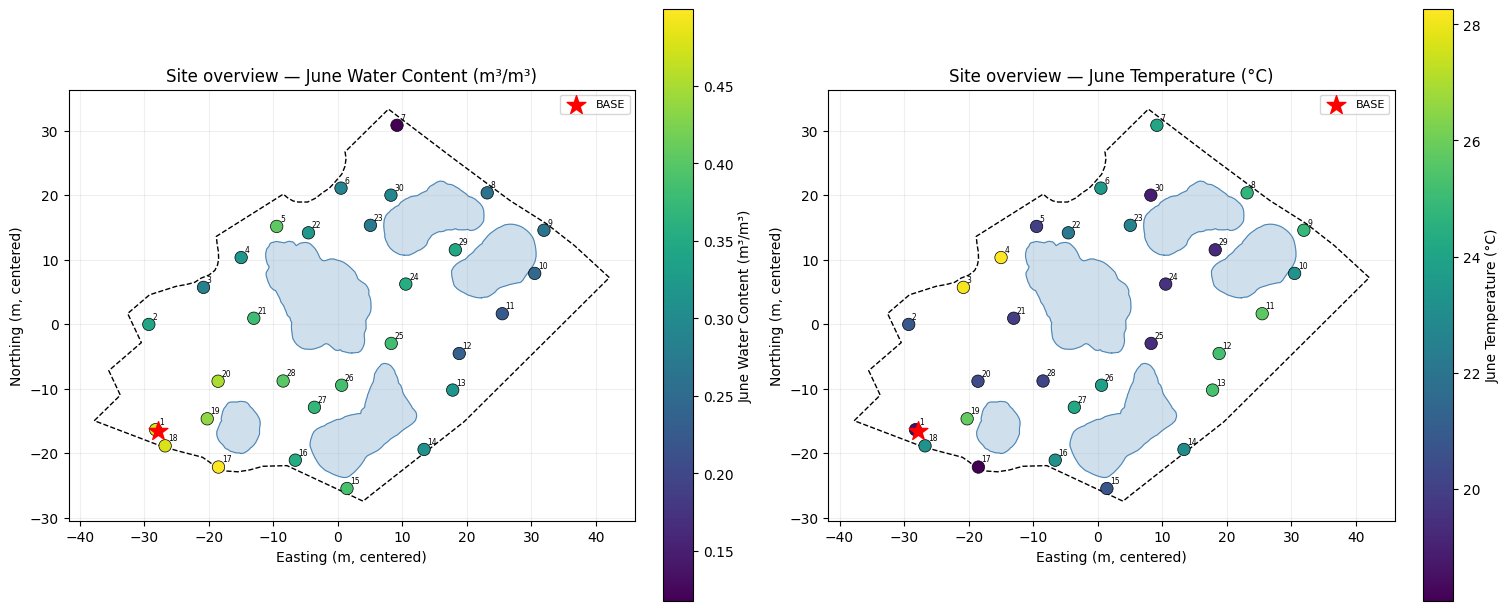

In [6]:
# -------------------------------------------
# 5) Center UTM coordinates; build dense eval grid; site overview
# -------------------------------------------

# Sort by GCP number so array index i+1 = GCP i+1 (node 0 = BASE)
merged_sorted = merged.sort_values("gcp_num").reset_index(drop=True)

cx = merged_sorted["x"].mean()
cy = merged_sorted["y"].mean()
merged_sorted["xc"] = merged_sorted["x"] - cx
merged_sorted["yc"] = merged_sorted["y"] - cy

base_xc = base_row["x"] - cx
base_yc = base_row["y"] - cy

print(f"Site centroid (UTM-32617): ({cx:.2f}, {cy:.2f})")
print(f"GCP x span: {merged_sorted['xc'].min():.1f} — {merged_sorted['xc'].max():.1f} m  "
      f"(range {(merged_sorted['xc'].max()-merged_sorted['xc'].min()):.1f} m)")
print(f"GCP y span: {merged_sorted['yc'].min():.1f} — {merged_sorted['yc'].max():.1f} m  "
      f"(range {(merged_sorted['yc'].max()-merged_sorted['yc'].min()):.1f} m)")
print(f"BASE (centered): ({base_xc:.1f}, {base_yc:.1f})")

# Dense eval grid for kriging maps
PAD = 5.0
xg = np.linspace(merged_sorted["xc"].min() - PAD, merged_sorted["xc"].max() + PAD, 60)
yg = np.linspace(merged_sorted["yc"].min() - PAD, merged_sorted["yc"].max() + PAD, 60)
X1g, X2g = np.meshgrid(xg, yg)
eval_pts_grid = np.column_stack([X1g.ravel(), X2g.ravel()])
print(f"Eval grid: {len(eval_pts_grid)} pts ({len(xg)}×{len(yg)})")


def overlay_pools(ax):
    for geom in pools.geometry:
        geom_c = shp_translate(geom, xoff=-cx, yoff=-cy)
        xs, ys = geom_c.exterior.xy
        ax.fill(xs, ys, alpha=0.25, color="steelblue")
        ax.plot(xs, ys, color="steelblue", linewidth=0.7)

def overlay_area(ax):
    for geom in area.geometry:
        geom_c = shp_translate(geom, xoff=-cx, yoff=-cy)
        xs, ys = geom_c.exterior.xy
        ax.plot(xs, ys, "k--", linewidth=1.0)


fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

for ax, var, title in zip(axes,
                           ["WC_june", "Temp_june"],
                           ["June Water Content (m³/m³)", "June Temperature (°C)"]):
    overlay_pools(ax)
    overlay_area(ax)
    sc = ax.scatter(merged_sorted["xc"], merged_sorted["yc"],
                    c=merged_sorted[var], cmap="viridis",
                    s=80, zorder=5, edgecolor="k", linewidth=0.5)
    for _, row in merged_sorted.iterrows():
        ax.annotate(str(int(row["gcp_num"])),
                    (row["xc"] + 0.5, row["yc"] + 0.5),
                    fontsize=5.5, ha="left", va="bottom", color="k")
    ax.scatter([base_xc], [base_yc], marker="*", s=200, color="red", zorder=6, label="BASE")
    fig.colorbar(sc, ax=ax, label=title)
    ax.set_title(f"Site overview — {title}")
    ax.set_xlabel("Easting (m, centered)")
    ax.set_ylabel("Northing (m, centered)")
    ax.legend(fontsize=8)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.show()

## 5b) Orthoimagery Ground-Truth Overlay

Independent CRS verification: GCP coordinates and pool geometries overlaid on
`WestCampusOrthoimagery.tif` (2 cm/px aerial survey, Jenny Cheng's West Campus
field site).  This is the only check that catches a systematic coordinate error —
all prior checks verify *internal* consistency (data matches shapefile, matches join
table) but would miss a wrong-but-self-consistent CRS that shifts the whole site
off its true ground position.

The ortho uses a compound CRS (WGS 84 / UTM zone 17N + EGM96 height).  Its 2D
horizontal component is EPSG:32617 — the project working CRS — so no reprojection
is needed.  Alignment is verified below both numerically (site area inside ortho
bounding box) and visually.


=== Orthoimagery metadata ===
  File:   WestCampusOrthoimagery.tif  (3.1 GB)
  Shape:  30,000 x 34,000 px  at  1.9 cm/px  (3-band RGB uint8)
  CRS:    compound WGS84 / UTM zone 17N + EGM96 height
          horizontal component = EPSG:32617 (project CRS — no reprojection needed)
  Bounds: W=586696.0  E=587342.7  S=4790571.5  N=4791142.1

=== CRS alignment check ===
  Site area total bounds: [np.float64(587089.1), np.float64(4790879.6), np.float64(587168.9), np.float64(4790940.4)]
  Site area covered by ortho: 100.0%
  PASS — site fully inside ortho; horizontal CRS matches EPSG:32617.


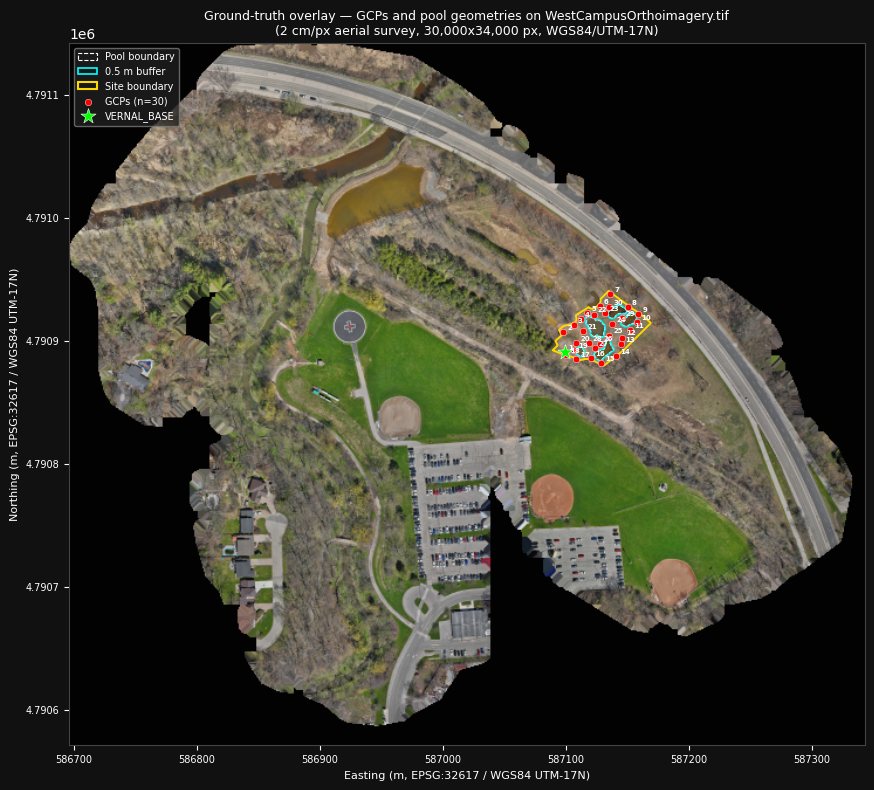

Figure saved: C:\Users\lukhs\Documents\Coding\Internships\ARCO\GP-Planning\results\nb05_ortho_overlay.png


In [7]:
# -------------------------------------------
# 5b) Orthoimagery ground-truth overlay
# -------------------------------------------
# Verify that GCP coordinates and pool geometries land on the correct
# ground positions by overlaying them on the 2 cm/px orthophotograph.

import rasterio
from rasterio.enums import Resampling
from shapely.geometry import box as shapely_box

ORTHO_PATH = os.path.join(REFS_DIR, "WestCampusOrthoimagery.tif")

# ── 1. Metadata + CRS check ──────────────────────────────────────────────────
with rasterio.open(ORTHO_PATH) as src:
    ob         = src.bounds
    ortho_h    = src.height
    ortho_w    = src.width
    ortho_res  = abs(src.transform.a)

    # CRS: compound WGS84/UTM-17N + EGM96 vertical — EPSG() returns None for
    # compound CRS; the 2D horizontal component IS EPSG:32617, same as project.
    # Verify by checking the site area falls inside the ortho bounding box.
    ortho_box   = shapely_box(ob.left, ob.bottom, ob.right, ob.top)
    site_box    = shapely_box(*area.total_bounds)
    overlap_pct = ortho_box.intersection(site_box).area / site_box.area * 100

    print("=== Orthoimagery metadata ===")
    print(f"  File:   WestCampusOrthoimagery.tif  "
          f"({os.path.getsize(ORTHO_PATH)/1e9:.1f} GB)")
    print(f"  Shape:  {ortho_h:,} x {ortho_w:,} px  at  {ortho_res*100:.1f} cm/px  "
          f"(3-band RGB uint8)")
    print(f"  CRS:    compound WGS84 / UTM zone 17N + EGM96 height")
    print(f"          horizontal component = EPSG:32617 (project CRS — no reprojection needed)")
    print(f"  Bounds: W={ob.left:.1f}  E={ob.right:.1f}  "
          f"S={ob.bottom:.1f}  N={ob.top:.1f}")

    print(f"\n=== CRS alignment check ===")
    print(f"  Site area total bounds: {[round(v, 1) for v in area.total_bounds]}")
    print(f"  Site area covered by ortho: {overlap_pct:.1f}%")
    if overlap_pct > 99.0:
        print("  PASS — site fully inside ortho; horizontal CRS matches EPSG:32617.")
    elif overlap_pct > 50.0:
        print(f"  PARTIAL ({overlap_pct:.1f}%) — review figure for misalignment.")
    else:
        print("  FAIL — no meaningful overlap; likely CRS mismatch. Investigate before proceeding.")

    # Read at 1/50 resolution (~600 x 680 px) for display — avoids loading 3 GB.
    SCALE = 50
    out_h = max(1, ortho_h // SCALE)
    out_w = max(1, ortho_w // SCALE)
    rgb   = src.read([1, 2, 3],
                     out_shape=(3, out_h, out_w),
                     resampling=Resampling.average)

# GCPs: split base vs measurement points (UTM-32617, un-centered)
gcp_non_base = gcps[~gcps["is_base"]].copy()
gcp_base_pts = gcps[ gcps["is_base"]].copy()

# ── 2. Overlay figure ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 8))
fig.patch.set_facecolor("#111111")
ax.set_facecolor("#111111")

extent = [ob.left, ob.right, ob.bottom, ob.top]
ax.imshow(rgb.transpose(1, 2, 0), extent=extent, origin="upper",
          interpolation="bilinear", alpha=0.88, aspect="equal")

# Pool raw boundaries (dashed white, thin)
pool_bounds.plot(ax=ax, facecolor="none", edgecolor="white", linewidth=0.7,
                 linestyle="--", zorder=2)
# Pool 0.5 m buffers (cyan)
pools.plot(ax=ax, facecolor="none", edgecolor="cyan", linewidth=1.1, zorder=3,
           alpha=0.85)
# Site boundary (gold)
area.plot(ax=ax, facecolor="none", edgecolor="gold", linewidth=1.4, zorder=4)

# GCPs — red dots + white number labels
for _, row in gcp_non_base.iterrows():
    ax.scatter(row.geometry.x, row.geometry.y,
               c="red", s=22, zorder=6, edgecolors="white", linewidths=0.3)
    ax.annotate(str(int(row["gcp_num"])),
                xy=(row.geometry.x, row.geometry.y),
                xytext=(3, 2), textcoords="offset points",
                fontsize=5, color="white", fontweight="bold", zorder=7)

# VERNAL_BASE — lime star
ax.scatter(gcp_base_pts.geometry.x.values, gcp_base_pts.geometry.y.values,
           c="lime", marker="*", s=130, zorder=8, edgecolors="white",
           linewidths=0.4, label="VERNAL_BASE")

import matplotlib.patches as mpatches
_legend_handles = [
    mpatches.Patch(facecolor="none", edgecolor="white", linestyle="--",
                   linewidth=0.8, label="Pool boundary"),
    mpatches.Patch(facecolor="none", edgecolor="cyan",
                   linewidth=1.2, label="0.5 m buffer"),
    mpatches.Patch(facecolor="none", edgecolor="gold",
                   linewidth=1.5, label="Site boundary"),
    plt.scatter([], [], c="red", s=22, edgecolors="white", linewidths=0.3,
                label="GCPs (n=30)"),
    plt.scatter([], [], c="lime", marker="*", s=130, edgecolors="white",
                linewidths=0.4, label="VERNAL_BASE"),
]
ax.legend(handles=_legend_handles, loc="upper left", fontsize=7, framealpha=0.75,
          facecolor="#222222", edgecolor="gray", labelcolor="white")
ax.set_xlabel("Easting (m, EPSG:32617 / WGS84 UTM-17N)", color="white", fontsize=8)
ax.set_ylabel("Northing (m, EPSG:32617 / WGS84 UTM-17N)", color="white", fontsize=8)
ax.set_title(
    f"Ground-truth overlay — GCPs and pool geometries on WestCampusOrthoimagery.tif\n"
    f"(2 cm/px aerial survey, {ortho_h:,}x{ortho_w:,} px, WGS84/UTM-17N)",
    color="white", fontsize=9,
)
ax.tick_params(colors="white", labelsize=7)
for sp in ax.spines.values():
    sp.set_edgecolor("#444444")

plt.tight_layout()

ortho_fig_dir = os.path.join(project_root, "results")
os.makedirs(ortho_fig_dir, exist_ok=True)
ortho_fig_path = os.path.join(ortho_fig_dir, "nb05_ortho_overlay.png")
plt.savefig(ortho_fig_path, dpi=150, bbox_inches="tight",
            facecolor=fig.get_facecolor())
plt.show()
print(f"Figure saved: {ortho_fig_path}")


## 6) Routing Graph

Nodes: node 0 = VERNAL_BASE, nodes 1–30 = GCPs 1–30.
Edges: full pairwise connectivity pruned for edges whose interior crosses any
pool buffer (0.5 m polygon).  Edge weight = Euclidean distance / travel_speed.

Visibility graph: 83 nodes (31 GCPs + 52 pool-buffer waypoints), 960 edges



=== Routing Graph (detour travel model) ===
Nodes: 31  (0=BASE, 1-30=GCPs)
Candidate edges: 465
  Straight (direct OK):             148  (31.8%)
  Detour-routed (was pool-blocked):  317  (68.2%)
  Infeasible (no detour found):        0  (0.0%)
Graph edges total: 465  Connected: True
Detour inflation: mean=1.07x  max=1.59x  min=1.00x
BASE can reach all 30 GCPs: OK
Travel times (finite): min=0.0s  mean=30.9s  max=70.5s
BASE to GCPs: min=0.4s  max=70.2s


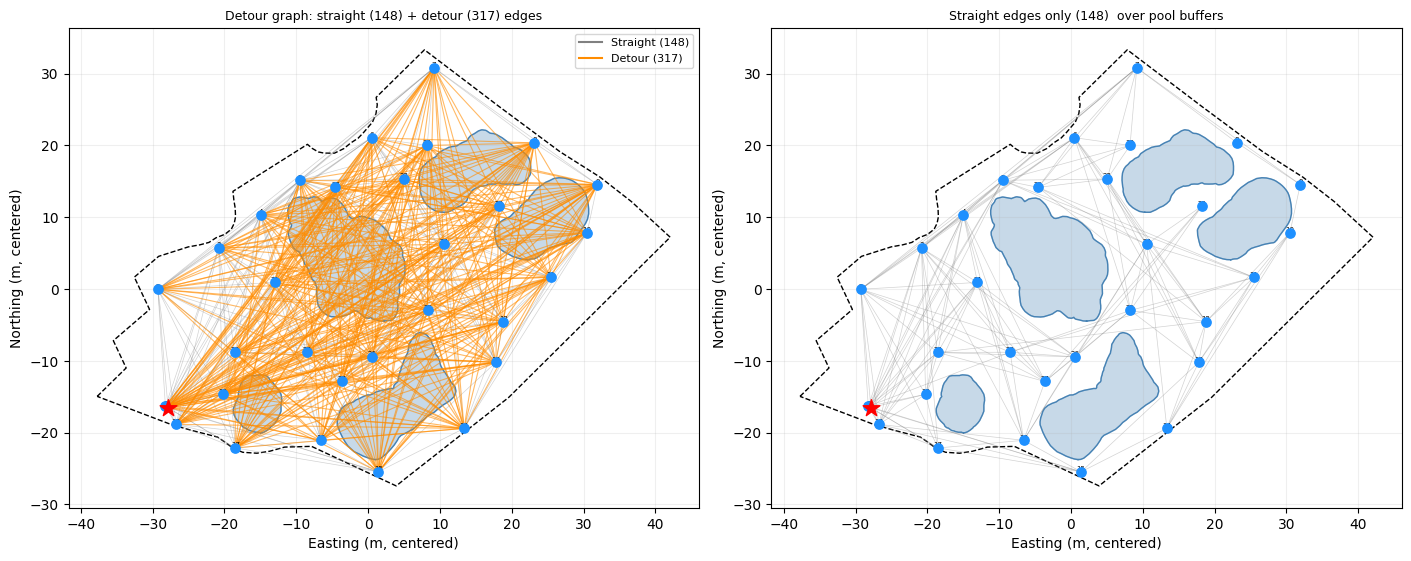

Stored 317 detour path geometries (centered UTM).


In [8]:
# -------------------------------------------
# 6) Routing graph — detour-based travel model
# -------------------------------------------
# Previously, edges crossing a pool buffer were DELETED (317/465 pruned), which
# wrongly modelled "can't go straight through" as "can't go at all." Now each
# pool-crossing edge is given the travel time of the shortest detour around the
# pool buffer boundaries via a visibility graph. Only edges with no feasible
# detour (should be zero on this site) are removed.

node_xc = np.concatenate([[base_xc], merged_sorted["xc"].values])
node_yc = np.concatenate([[base_yc], merged_sorted["yc"].values])
node_coords = np.column_stack([node_xc, node_yc])   # (31,2) centered UTM
n_nodes = len(node_coords)

# ── Build visibility graph for detour routing ─────────────────────────────────
# Extract exterior vertices of each pool-buffer polygon, offset 0.7 m outward
# from the polygon centroid so they lie just outside the nogo_zone boundary.
geoms_list = (list(nogo_zone.geoms)
              if nogo_zone.geom_type == 'MultiPolygon' else [nogo_zone])
poly_wp_abs = []       # waypoints in absolute UTM
for poly in geoms_list:
    simp = poly.simplify(0.5)   # 0.5 m tolerance reduces vertex count
    ctr  = poly.centroid
    for pt in list(simp.exterior.coords)[:-1]:
        dx = pt[0] - ctr.x;  dy = pt[1] - ctr.y
        nrm = max((dx**2 + dy**2)**0.5, 1e-6)
        poly_wp_abs.append((pt[0] + 0.7*dx/nrm, pt[1] + 0.7*dy/nrm))

# Node absolute-UTM positions (so shapely comparisons match nogo_zone)
node_abs = [(node_xc[i]+cx, node_yc[i]+cy) for i in range(n_nodes)]
vis_pos  = node_abs + poly_wp_abs   # GCP nodes 0..n_nodes-1, then polygon waypoints
n_vis    = len(vis_pos)

vis_G = nx.Graph()
vis_G.add_nodes_from(range(n_vis))
for i in range(n_vis):
    for j in range(i+1, n_vis):
        seg = LineString([vis_pos[i], vis_pos[j]])
        if not seg.crosses(nogo_zone):
            d = float(np.linalg.norm(np.array(vis_pos[i]) - np.array(vis_pos[j])))
            vis_G.add_edge(i, j, weight=d)

print(f"Visibility graph: {n_vis} nodes "
      f"({n_nodes} GCPs + {len(poly_wp_abs)} pool-buffer waypoints), "
      f"{vis_G.number_of_edges()} edges")

# ── Build routing graph with detour costs ─────────────────────────────────────
G = nx.Graph()
for i in range(n_nodes):
    G.add_node(i, pos=(node_xc[i], node_yc[i]))

n_total = n_nodes * (n_nodes - 1) // 2
n_straight = 0;  n_detour = 0;  n_infeasible = 0
straight_edges = [];  detour_edges = [];  infeasible_edges = []
detour_ratios  = []   # detour_dist / direct_dist per edge

for i in range(n_nodes):
    for j in range(i+1, n_nodes):
        seg_abs     = LineString([node_abs[i], node_abs[j]])
        direct_dist = float(np.linalg.norm(node_coords[i] - node_coords[j]))
        if not seg_abs.crosses(nogo_zone):
            G.add_edge(i, j, weight=direct_dist/TRAVEL_SPEED, detour=False)
            straight_edges.append((i, j));  n_straight += 1
        else:
            try:
                det_dist = nx.shortest_path_length(vis_G, i, j, weight='weight')
                G.add_edge(i, j, weight=det_dist/TRAVEL_SPEED, detour=True)
                detour_edges.append((i, j))
                detour_ratios.append(det_dist / max(direct_dist, 1e-6))
                n_detour += 1
            except (nx.NetworkXNoPath, nx.NodeNotFound):
                infeasible_edges.append((i, j));  n_infeasible += 1

tt = travel_time_matrix(G)
np.fill_diagonal(tt, 0.0)
tt[np.isinf(tt)] = 9999.0

# Backward-compat aliases used by summary cell
n_pruned     = n_infeasible
pruned_edges = infeasible_edges
retained_edges = straight_edges + detour_edges

print(f"\n=== Routing Graph (detour travel model) ===")
print(f"Nodes: {n_nodes}  (0=BASE, 1-30=GCPs)")
print(f"Candidate edges: {n_total}")
print(f"  Straight (direct OK):            {n_straight:>4}  ({100*n_straight/n_total:.1f}%)")
print(f"  Detour-routed (was pool-blocked): {n_detour:>4}  ({100*n_detour/n_total:.1f}%)")
print(f"  Infeasible (no detour found):     {n_infeasible:>4}  ({100*n_infeasible/n_total:.1f}%)")
print(f"Graph edges total: {G.number_of_edges()}  Connected: {nx.is_connected(G)}")
if detour_ratios:
    print(f"Detour inflation: "
          f"mean={np.mean(detour_ratios):.2f}x  "
          f"max={np.max(detour_ratios):.2f}x  "
          f"min={np.min(detour_ratios):.2f}x")

unreachable = [i for i in range(1, n_nodes) if tt[BASE_NODE, i] >= 9999]
if unreachable:
    print(f"WARNING: nodes unreachable from BASE: {unreachable}")
else:
    print(f"BASE can reach all {n_nodes-1} GCPs: OK")

fin = tt[tt < 9999]
print(f"Travel times (finite): min={fin.min():.1f}s  mean={fin.mean():.1f}s  max={fin.max():.1f}s")
print(f"BASE to GCPs: min={tt[BASE_NODE,1:].min():.1f}s  max={tt[BASE_NODE,1:].max():.1f}s")

# ── Visualisation ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
from matplotlib.lines import Line2D

for ax, show_det, title in [
    (axes[0], True,  f"Detour graph: straight ({n_straight}) + detour ({n_detour}) edges"),
    (axes[1], False, f"Straight edges only ({n_straight})  over pool buffers"),
]:
    for geom in pools.geometry:
        gc = shp_translate(geom, xoff=-cx, yoff=-cy)
        xs, ys = gc.exterior.xy
        ax.fill(xs, ys, alpha=0.30, color="steelblue")
        ax.plot(xs, ys, "steelblue", linewidth=1.0)
    overlay_area(ax)
    for (i, j) in straight_edges:
        ax.plot([node_xc[i], node_xc[j]], [node_yc[i], node_yc[j]],
                color="gray", linewidth=0.5, alpha=0.35)
    if show_det:
        for (i, j) in detour_edges:
            ax.plot([node_xc[i], node_xc[j]], [node_yc[i], node_yc[j]],
                    color="darkorange", linewidth=0.8, alpha=0.6)
    ax.scatter(node_xc[1:], node_yc[1:], s=45, color="dodgerblue", zorder=4)
    ax.scatter([node_xc[0]], [node_yc[0]], s=160, marker="*", color="red", zorder=5)
    for i in range(1, n_nodes):
        ax.annotate(str(i), (node_xc[i], node_yc[i]),
                    fontsize=5, ha="center", va="bottom")
    if show_det:
        ax.legend(handles=[
            Line2D([0],[0], color="gray",       linewidth=1.5, label=f"Straight ({n_straight})"),
            Line2D([0],[0], color="darkorange",  linewidth=1.5, label=f"Detour ({n_detour})"),
        ], fontsize=8)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("Easting (m, centered)");  ax.set_ylabel("Northing (m, centered)")
    ax.set_aspect("equal");  ax.grid(alpha=0.2)
plt.show()

# ── Detour path geometries for correct visualization ──────────────────────────
# For each pool-crossing edge, store the actual visibility-graph path in
# centered UTM so plots can draw the true around-the-pool route.
detour_vis_paths = {}    # (min_i, max_j) -> [(xc, yc), ...] centered UTM
detour_edge_set  = set() # canonical (min_i, max_j) pairs that are pool-crossing
for (i, j) in detour_edges:
    key = (min(i, j), max(i, j))
    vis_nodes = nx.shortest_path(vis_G, i, j, weight='weight')
    detour_vis_paths[key] = [(vis_pos[v][0]-cx, vis_pos[v][1]-cy) for v in vis_nodes]
    detour_edge_set.add(key)
print(f"Stored {len(detour_vis_paths)} detour path geometries (centered UTM).")


In [9]:
# -------------------------------------------
# 6b) Task 1: Routing matrix verification
# -------------------------------------------
# Confirm planners use DETOUR costs (not straight-line) for pool-crossing edges.
# Routing is correct iff tt[i,j] == detour_edge_cost (not direct_dist/speed).
# Paths may still draw straight lines through pools in naive plots —
# that is a visualisation bug only, not a routing bug.

print("=== Task 1: Travel-time matrix verification ===")
print("Checking pool-crossing pairs: tt[i,j] should equal detour cost, not direct cost")
print(f"  {'edge':>10}  {'direct(s)':>10}  {'det_edge(s)':>12}  {'tt[i,j](s)':>11}  correct?")
print("-" * 65)
n_ok = 0
sample = sorted(detour_edges)[:8]
for (i, j) in sample:
    direct_t = float(np.linalg.norm(node_coords[i] - node_coords[j])) / TRAVEL_SPEED
    actual   = float(tt[i, j])
    det_t    = nx.shortest_path_length(vis_G, i, j, weight='weight') / TRAVEL_SPEED
    ok       = abs(actual - det_t) < 0.05 or actual < det_t  # shorter indirect OK too
    if ok: n_ok += 1
    print(f"  ({i:2d},{j:2d})   {direct_t:>10.2f}  {det_t:>12.2f}  {actual:>11.2f}  {'YES' if ok else 'NO — BUG'}")

print()
if n_ok == len(sample):
    print("CONCLUSION: ROUTING IS CORRECT — planners use detour travel-time matrix.")
    print("  Straight-line path drawings crossing pool areas = visualisation bug only.")
    print("  Fix: draw detour edges along actual pool-avoiding geometry (see plots below).")
else:
    print("WARNING: some edges use straight-line cost — routing may be incorrect!")


=== Task 1: Travel-time matrix verification ===
Checking pool-crossing pairs: tt[i,j] should equal detour cost, not direct cost
        edge   direct(s)   det_edge(s)   tt[i,j](s)  correct?
-----------------------------------------------------------------
  ( 0, 6)        47.11         48.04        48.04  YES
  ( 0, 7)        60.11         60.78        60.78  YES
  ( 0, 8)        62.95         66.51        66.51  YES
  ( 0, 9)        67.40         70.22        70.22  YES
  ( 0,10)        63.26         63.57        63.57  YES
  ( 0,11)        56.35         56.45        56.45  YES
  ( 0,12)        48.19         48.55        48.55  YES
  ( 0,13)        46.10         48.47        48.47  YES

CONCLUSION: ROUTING IS CORRECT — planners use detour travel-time matrix.
  Straight-line path drawings crossing pool areas = visualisation bug only.
  Fix: draw detour edges along actual pool-avoiding geometry (see plots below).


## 7) GP Fitting (Learned Hyperparameters, June Campaign)

Fit an exact GP (GPyTorch, RBF kernel with ARD, constant mean) to the
June 10–19 WC measurements.  Inputs are centered UTM coordinates (meters).
Targets are standardised before training.

In [10]:
# -------------------------------------------
# 7) GP model and training
# -------------------------------------------

class _ExactGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super().__init__(train_x, train_y, likelihood)
        self.mean_module  = gpytorch.means.ConstantMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.RBFKernel(ard_num_dims=2)
        )
    def forward(self, x):
        return gpytorch.distributions.MultivariateNormal(
            self.mean_module(x), self.covar_module(x)
        )


train_pts  = merged_sorted[["xc", "yc"]].values.astype(float)
var_col    = "WC_june" if PRIMARY_VARIABLE == "wc" else "Temp_june"
train_vals = merged_sorted[var_col].values.astype(float)

train_x = torch.tensor(train_pts, dtype=torch.float32)
train_y = torch.tensor(train_vals, dtype=torch.float32)
y_mean  = float(train_y.mean())
y_std   = float(train_y.std().clamp_min(1e-6))
train_y_s = (train_y - y_mean) / y_std

likelihood = gpytorch.likelihoods.GaussianLikelihood()
model      = _ExactGPModel(train_x, train_y_s, likelihood)
model.train(); likelihood.train()

optimizer = torch.optim.Adam(model.parameters(), lr=GP_LR)
mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

mll_init = None
for it in range(GP_TRAIN_ITERS):
    optimizer.zero_grad()
    loss = -mll(model(train_x), train_y_s)
    if it == 0: mll_init = float(-loss.item())
    loss.backward()
    optimizer.step()
mll_final = float(-loss.item())

model.eval(); likelihood.eval()

ls  = model.covar_module.base_kernel.lengthscale.detach().numpy().ravel()
os_ = float(model.covar_module.outputscale.detach().item())
nv  = float(likelihood.noise.detach().item())
mc  = float(model.mean_module.constant.detach().item()) * y_std + y_mean

print(f"=== GP Fit (n={len(train_pts)}, variable={var_col}) ===")
print(f"  y_mean = {y_mean:.4f}  y_std = {y_std:.4f}  (standardisation)")
print(f"  lengthscale_x = {ls[0]:.2f} m  (E-W)")
print(f"  lengthscale_y = {ls[1]:.2f} m  (N-S)")
print(f"  outputscale   = {os_:.4f}  (in standardised space)")
print(f"  noise_var     = {nv:.4f}  (in standardised space)")
print(f"  mean_constant = {mc:.4f}  (original units)")
print(f"  MLL: {mll_init:.3f} → {mll_final:.3f}  (improvement {mll_final-mll_init:.3f})")

=== GP Fit (n=30, variable=WC_june) ===
  y_mean = 0.3398  y_std = 0.0851  (standardisation)
  lengthscale_x = 8.35 m  (E-W)
  lengthscale_y = 7.45 m  (N-S)
  outputscale   = 0.8708  (in standardised space)
  noise_var     = 0.0360  (in standardised space)
  mean_constant = 0.3319  (original units)
  MLL: -1.431 → -1.100  (improvement 0.331)


## 8) LOO-CV Calibration

Analytical leave-one-out cross-validation using the learned hyperparameters
(no re-training).  Uses the LOO formulae for Gaussian processes:

$$\hat\mu_{-i} = y_i - \alpha_i / [K^{-1}]_{ii}, \qquad
\hat\sigma^2_{-i} = 1 / [K^{-1}]_{ii}$$

where $K = K_\theta + \sigma^2 I$ and $\alpha = K^{-1}\mathbf{y}$.

=== LOO-CV (n=30) ===
  LOO-RMSE    = 0.0589 m³/m³
  LOO-MAE     = 0.0432 m³/m³
  Coverage-95 = 93.3%  (ideal: 95%)
  Coverage-50 = 43.3%  (ideal: 50%)
  z-mean      = -0.046  z-std = 1.079


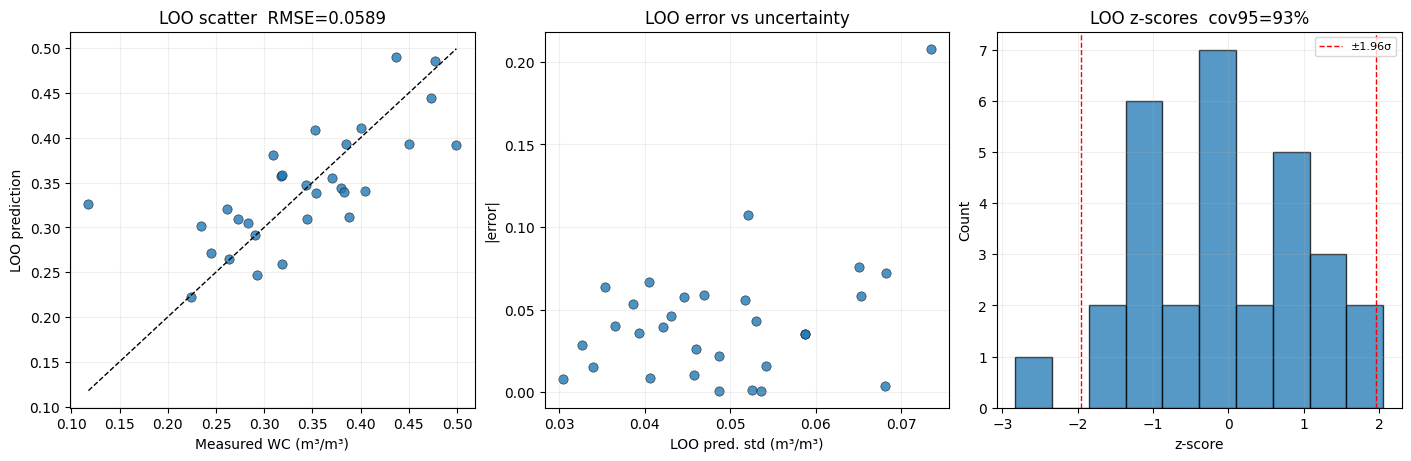

In [11]:
# -------------------------------------------
# 8) Analytical LOO-CV
# -------------------------------------------

with torch.no_grad():
    K_s = model.covar_module(train_x).evaluate().numpy()  # (30,30) in scaled space

K_noisy = K_s + nv * np.eye(len(train_vals))
K_inv   = np.linalg.inv(K_noisy)
alpha   = K_inv @ train_y_s.numpy()

loo_mean_s = train_y_s.numpy() - alpha / np.diag(K_inv)
loo_var_s  = 1.0 / np.diag(K_inv)

loo_mean = loo_mean_s * y_std + y_mean
loo_std  = np.sqrt(np.maximum(loo_var_s, 1e-12)) * y_std

actual     = train_vals
loo_rmse   = float(np.sqrt(np.mean((loo_mean - actual) ** 2)))
loo_mae    = float(np.mean(np.abs(loo_mean - actual)))
z_scores   = (actual - loo_mean) / np.maximum(loo_std, 1e-8)
cov95      = float(np.mean(np.abs(z_scores) <= 1.96))
picp_50    = float(np.mean(np.abs(z_scores) <= 0.674))

print(f"=== LOO-CV (n=30) ===")
print(f"  LOO-RMSE    = {loo_rmse:.4f} m³/m³")
print(f"  LOO-MAE     = {loo_mae:.4f} m³/m³")
print(f"  Coverage-95 = {100*cov95:.1f}%  (ideal: 95%)")
print(f"  Coverage-50 = {100*picp_50:.1f}%  (ideal: 50%)")
print(f"  z-mean      = {z_scores.mean():.3f}  z-std = {z_scores.std():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True)

lo = min(actual.min(), loo_mean.min()); hi = max(actual.max(), loo_mean.max())
axes[0].scatter(actual, loo_mean, s=45, alpha=0.8, edgecolor="k", linewidth=0.4)
axes[0].plot([lo, hi], [lo, hi], "k--", linewidth=1)
axes[0].set_xlabel("Measured WC (m³/m³)"); axes[0].set_ylabel("LOO prediction")
axes[0].set_title(f"LOO scatter  RMSE={loo_rmse:.4f}")
axes[0].grid(alpha=0.2)

axes[1].scatter(loo_std, np.abs(actual - loo_mean), s=45, alpha=0.8, edgecolor="k", linewidth=0.4)
axes[1].set_xlabel("LOO pred. std (m³/m³)"); axes[1].set_ylabel("|error|")
axes[1].set_title("LOO error vs uncertainty")
axes[1].grid(alpha=0.2)

axes[2].hist(z_scores, bins=10, edgecolor="k", alpha=0.75)
axes[2].axvline(-1.96, color="r", linestyle="--", linewidth=1)
axes[2].axvline(+1.96, color="r", linestyle="--", linewidth=1, label="±1.96σ")
axes[2].set_xlabel("z-score"); axes[2].set_ylabel("Count")
axes[2].set_title(f"LOO z-scores  cov95={100*cov95:.0f}%")
axes[2].legend(fontsize=8); axes[2].grid(alpha=0.2)
plt.show()

## 9) GP Posterior Map (Kriging over Site)

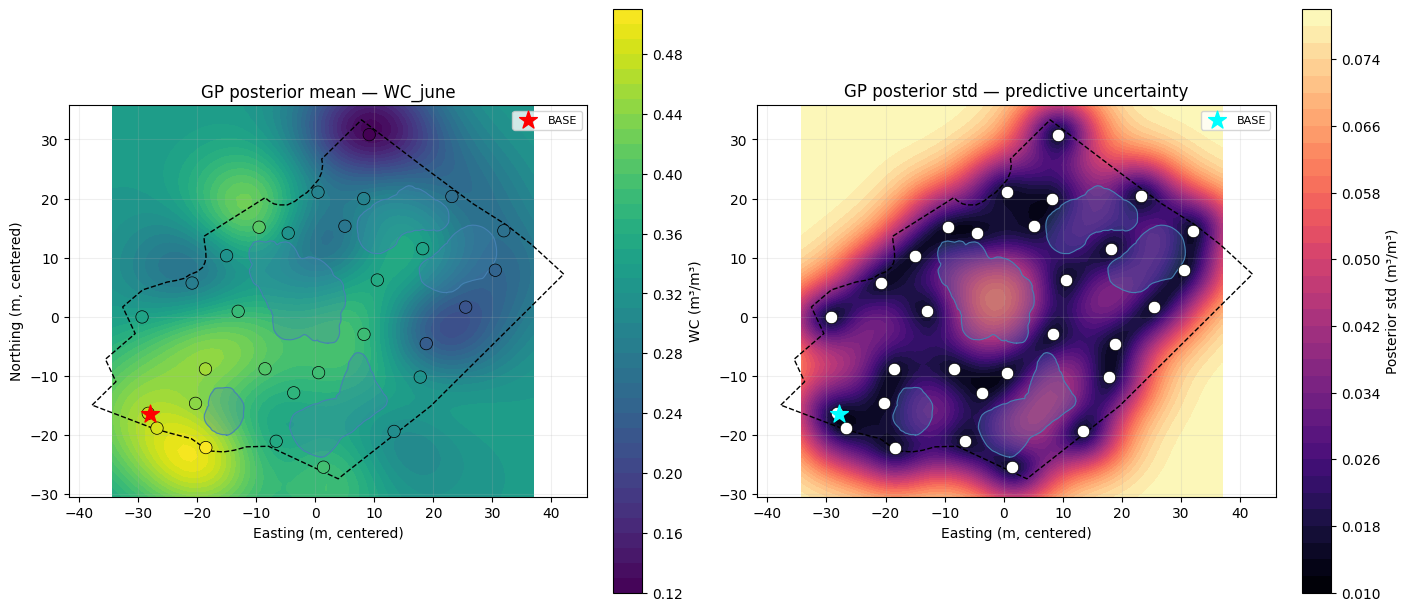

Posterior std at each GCP (ordered by GCP number):
  GCP  1: 0.0140 m³/m³
  GCP  2: 0.0157 m³/m³
  GCP  3: 0.0152 m³/m³
  GCP  4: 0.0149 m³/m³
  GCP  5: 0.0144 m³/m³
  GCP  6: 0.0154 m³/m³
  GCP  7: 0.0157 m³/m³
  GCP  8: 0.0156 m³/m³
  GCP  9: 0.0154 m³/m³
  GCP 10: 0.0151 m³/m³
  GCP 11: 0.0152 m³/m³
  GCP 12: 0.0148 m³/m³
  GCP 13: 0.0151 m³/m³
  GCP 14: 0.0157 m³/m³
  GCP 15: 0.0156 m³/m³
  GCP 16: 0.0153 m³/m³
  GCP 17: 0.0153 m³/m³
  GCP 18: 0.0137 m³/m³
  GCP 19: 0.0147 m³/m³
  GCP 20: 0.0150 m³/m³
  GCP 21: 0.0155 m³/m³
  GCP 22: 0.0145 m³/m³
  GCP 23: 0.0147 m³/m³
  GCP 24: 0.0154 m³/m³
  GCP 25: 0.0154 m³/m³
  GCP 26: 0.0148 m³/m³
  GCP 27: 0.0142 m³/m³
  GCP 28: 0.0151 m³/m³
  GCP 29: 0.0155 m³/m³
  GCP 30: 0.0150 m³/m³


In [12]:
# -------------------------------------------
# 9) GP posterior map on dense eval grid
import warnings
warnings.filterwarnings("ignore", category=gpytorch.utils.warnings.GPInputWarning)
# -------------------------------------------

eval_x = torch.tensor(eval_pts_grid, dtype=torch.float32)
with torch.no_grad(), gpytorch.settings.fast_pred_var():
    pred_grid = model(eval_x)
    mean_map_s = pred_grid.mean.numpy()
    var_map_s  = pred_grid.variance.numpy()

mean_map = (mean_map_s * y_std + y_mean).reshape(X1g.shape)
std_map  = (np.sqrt(np.maximum(var_map_s, 1e-12)) * y_std).reshape(X1g.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

c0 = axes[0].contourf(X1g, X2g, mean_map, levels=40, cmap="viridis")
overlay_pools(axes[0]); overlay_area(axes[0])
axes[0].scatter(merged_sorted["xc"], merged_sorted["yc"],
                c=train_vals, cmap="viridis", s=80, edgecolor="k", linewidth=0.5, zorder=5,
                vmin=mean_map.min(), vmax=mean_map.max())
axes[0].scatter([base_xc], [base_yc], s=180, marker="*", color="red", zorder=6, label="BASE")
axes[0].set_title(f"GP posterior mean — {var_col}")
axes[0].set_xlabel("Easting (m, centered)"); axes[0].set_ylabel("Northing (m, centered)")
axes[0].legend(fontsize=8); axes[0].set_aspect("equal"); axes[0].grid(alpha=0.2)
fig.colorbar(c0, ax=axes[0], label="WC (m³/m³)")

c1 = axes[1].contourf(X1g, X2g, std_map, levels=40, cmap="magma")
overlay_pools(axes[1]); overlay_area(axes[1])
axes[1].scatter(merged_sorted["xc"], merged_sorted["yc"],
                s=80, c="white", edgecolor="k", linewidth=0.5, zorder=5)
axes[1].scatter([base_xc], [base_yc], s=180, marker="*", color="cyan", zorder=6, label="BASE")
axes[1].set_title("GP posterior std — predictive uncertainty")
axes[1].set_xlabel("Easting (m, centered)")
axes[1].legend(fontsize=8); axes[1].set_aspect("equal"); axes[1].grid(alpha=0.2)
fig.colorbar(c1, ax=axes[1], label="Posterior std (m³/m³)")
plt.show()

# Bar chart: posterior std at each GCP (before any path is planned)
node_x_t = torch.tensor(node_coords[1:], dtype=torch.float32)  # GCPs only
with torch.no_grad(), gpytorch.settings.fast_pred_var():
    pred_gcp = model(node_x_t)
    std_at_gcps = (np.sqrt(np.maximum(pred_gcp.variance.numpy(), 1e-12)) * y_std)

print("Posterior std at each GCP (ordered by GCP number):")
for i, s in enumerate(std_at_gcps):
    print(f"  GCP {i+1:2d}: {s:.4f} m³/m³")

## 10) K_all for GRG + Budget Calibration

The GRG objective is I(y_A; f_V | y_X) computed from the learned GP kernel.
All computations are in standardised space (consistent with `nv`). 

In [13]:
# -------------------------------------------
# 10) K_all (31×31) and budget calibration
# -------------------------------------------

# K_all in standardised space, shape (31, 31): node 0=BASE, 1-30=GCPs
nodes_x = torch.tensor(node_coords, dtype=torch.float32)
with torch.no_grad():
    K_all = model.covar_module(nodes_x).evaluate().numpy()
NOISE_VAR = nv  # noise variance in standardised space

print(f"K_all: {K_all.shape}  noise_var={NOISE_VAR:.4f}")
print(f"K_all diagonal (prior variance per node):")
print("  " + "  ".join(f"{v:.3f}" for v in np.diag(K_all)))

# Calibrate time budgets from travel-time matrix
rt_from_base = tt[BASE_NODE, 1:]  # one-way to each GCP
rt_from_base_finite = rt_from_base[rt_from_base < 9999]
min_rt = float(rt_from_base_finite.min()) * 2   # min feasible round-trip
max_rt = float(rt_from_base_finite.max()) * 2   # round-trip to farthest GCP

# 4 evenly-spaced budgets from ~1× to ~2.5× max round-trip
TIME_BUDGETS = [round(min_rt + i*(max_rt - min_rt) / 3, 0) for i in range(4)]
print(f"\nMin feasible round-trip: {min_rt:.1f}s  max round-trip: {max_rt:.1f}s")
print(f"TIME_BUDGETS: {TIME_BUDGETS}")

K_all: (31, 31)  noise_var=0.0360
K_all diagonal (prior variance per node):
  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871  0.871

Min feasible round-trip: 0.8s  max round-trip: 140.4s
TIME_BUDGETS: [1.0, 47.0, 94.0, 140.0]


## 11) GRG Tractability Check

In [14]:
# -------------------------------------------
# 11) GRG tractability check (Day-1 profiling step)
# -------------------------------------------
print(f"GRG tractability: depth={DEPTH}, n_tau_splits={N_TAU_SPLITS}")
print(f"Budget: {TIME_BUDGETS[0]:.0f}s (smallest feasible)\n")

cache_check = {}
t0 = time.perf_counter()
path_check = grg_plan(
    BASE_NODE, BASE_NODE, 0.0, TIME_BUDGETS[0],
    tt, K_all, NOISE_VAR,
    depth=DEPTH, n_tau_splits=N_TAU_SPLITS,
    _X_frozen=frozenset([BASE_NODE]),
    _mi_cache=cache_check,
)
elapsed_check = time.perf_counter() - t0

k_check = len(set(path_check) - {BASE_NODE}) if path_check else 0
mi_check = gp_mutual_information(
    frozenset(path_check) - {BASE_NODE}, K_all, NOISE_VAR, frozenset([BASE_NODE])
) if (path_check and k_check > 0) else 0.0

print(f"τ={TIME_BUDGETS[0]:.0f}s  elapsed={elapsed_check:.2f}s  "
      f"cache_size={len(cache_check)}")
print(f"path={path_check}  k={k_check}  MI={mi_check:.4f}")

if elapsed_check < 120:
    print(f"\nGO: {elapsed_check:.1f}s < 120s — safe to run full sweep")
else:
    print(f"\nCAUTION: {elapsed_check:.1f}s ≥ 120s — reduce n_tau_splits or depth")

GRG tractability: depth=4, n_tau_splits=2
Budget: 1s (smallest feasible)

τ=1s  elapsed=0.00s  cache_size=3
path=[0, 1, 0]  k=1  MI=0.3515

GO: 0.0s < 120s — safe to run full sweep


## 12) GRG Sweep — All Budgets

In [15]:
# -------------------------------------------
# 12) GRG sweep — depth=4, shared MI cache
# -------------------------------------------
# depth=4 → k_max = 2^4-1 = 15 intermediate waypoints (vs depth=3 → k_max=7).
# NN reaches k=18 at τ=157s; depth=3 was hard-capped at 7, not time-limited.
# Shared MI cache across budgets: MI(frozenset) is budget-independent, so
# cached lookups from τ=53s are reused at τ=157s for the same depth.

DEPTH_MAIN = 4    # authoritative depth for this notebook's main results

print(f"=== GRG Sweep  depth={DEPTH_MAIN}  N_TAU_SPLITS={N_TAU_SPLITS} ===")
print(f"  k_max = 2^{DEPTH_MAIN}-1 = {2**DEPTH_MAIN-1} intermediate waypoints")
print(f"  (depth=3 was capped at {2**3-1}; NN reaches 18 at τ=157s)")
print(f"{'τ (s)':>8}  {'elapsed':>10}  {'cache':>8}  {'k':>4}  {'MI':>10}  path")
print("-" * 80)

grg_cache_main = {}    # shared across budgets — populated from small budgets, reused for large

grg_results = {}
for tau in TIME_BUDGETS:
    t0   = time.perf_counter()
    path = grg_plan(
        BASE_NODE, BASE_NODE, 0.0, tau,
        tt, K_all, NOISE_VAR,
        depth=DEPTH_MAIN, n_tau_splits=N_TAU_SPLITS,
        _X_frozen=frozenset([BASE_NODE]),
        _mi_cache=grg_cache_main,
    )
    elapsed = time.perf_counter() - t0
    k  = len(set(path) - {BASE_NODE}) if path else 0
    mi = gp_mutual_information(
        frozenset(path) - {BASE_NODE}, K_all, NOISE_VAR, frozenset([BASE_NODE])
    ) if (path and k > 0) else 0.0
    grg_results[tau] = {"path": path, "k": k, "mi": mi,
                        "elapsed": elapsed, "depth": DEPTH_MAIN}
    flag = "  *** SLOW" if elapsed > 300 else ("  * slow" if elapsed > 60 else "")
    print(f"{tau:>8.0f}  {elapsed:>10.2f}s  {len(grg_cache_main):>8}  {k:>4}  {mi:>10.4f}  {str(path)[:60]}{flag}")

print(f"\nTotal cache entries after sweep: {len(grg_cache_main)}")
print("\nGRG depth=4 results:")
for tau in TIME_BUDGETS:
    g = grg_results[tau]
    cap = " AT CAP" if g["k"] >= 2**DEPTH_MAIN-1 else ""
    print(f"  τ={tau:.0f}s  k={g['k']}/{2**DEPTH_MAIN-1}{cap}  MI={g['mi']:.4f}  elapsed={g['elapsed']:.1f}s")


=== GRG Sweep  depth=4  N_TAU_SPLITS=2 ===
  k_max = 2^4-1 = 15 intermediate waypoints
  (depth=3 was capped at 7; NN reaches 18 at τ=157s)
   τ (s)     elapsed     cache     k          MI  path
--------------------------------------------------------------------------------
       1        0.00s         3     1      0.3515  [0, 1, 0]


      47        0.26s       187     5      4.9282  [0, 18, 19, 17, 20, 1, 0]


      94        6.69s      4459    10     12.1553  [0, 1, 18, 17, 19, 20, 28, 21, 4, 3, 2, 0]


     140       55.47s     59376    15     19.5844  [0, 19, 20, 21, 4, 5, 22, 23, 30, 24, 25, 26, 27, 16, 17, 18

Total cache entries after sweep: 59376

GRG depth=4 results:
  τ=1s  k=1/15  MI=0.3515  elapsed=0.0s
  τ=47s  k=5/15  MI=4.9282  elapsed=0.3s
  τ=94s  k=10/15  MI=12.1553  elapsed=6.7s
  τ=140s  k=15/15 AT CAP  MI=19.5844  elapsed=55.5s


## 13) Nearest-Neighbour Tour Baseline

In [16]:
# -------------------------------------------
# 13) Nearest-neighbour tour baseline
# -------------------------------------------
print(f"=== Nearest-Neighbour Baseline ===")
print(f"{'τ (s)':>8}  {'k':>4}  {'MI':>10}  path")
print("-" * 60)

nn_results = {}
for tau in TIME_BUDGETS:
    path_nn = nearest_neighbor_tour_fixed_end(BASE_NODE, BASE_NODE, tt, tau)
    k_nn    = len(set(path_nn) - {BASE_NODE})
    mi_nn   = gp_mutual_information(
        frozenset(path_nn) - {BASE_NODE}, K_all, NOISE_VAR, frozenset([BASE_NODE])
    ) if k_nn > 0 else 0.0
    nn_results[tau] = {"path": path_nn, "k": k_nn, "mi": mi_nn}
    print(f"{tau:>8.0f}  {k_nn:>4}  {mi_nn:>10.4f}  {path_nn}")

=== Nearest-Neighbour Baseline ===
   τ (s)     k          MI  path
------------------------------------------------------------
       1     1      0.3515  [0, 1, 0]
      47     5      4.9282  [0, 1, 18, 19, 20, 17, 0]
      94     9     10.2769  [0, 1, 18, 19, 20, 28, 27, 26, 25, 17, 0]
     140    11     13.5480  [0, 1, 18, 19, 20, 28, 27, 26, 25, 24, 29, 11, 0]


## 11b) GRG Depth Cap Analysis (Task 5)

At depth=3, GRG can represent at most 2³−1 = **7 intermediate waypoints**.
At τ=157s the NN greedy baseline visits 18 nodes, so the depth limit—not the
time budget—is the binding constraint for larger budgets.  This cell tests
depth=4 (max 15 intermediate) to assess tractability at the real 31-node scale.

In [17]:
# -------------------------------------------
# 11b) GRG depth-cap analysis
# -------------------------------------------
# The main sweep (Cell 27) already uses depth=4.
# This cell runs depth=3 at all budgets to quantify the improvement,
# and confirms τ=157s is time-limited at depth=4 but was waypoint-capped at depth=3.

print("=== Depth-cap analysis: depth=3 (historical) vs depth=4 (authoritative) ===")
print(f"  depth=3  k_max = {2**3-1} intermediate waypoints")
print(f"  depth=4  k_max = {2**4-1} intermediate waypoints")
print()

# Run depth=3 at all budgets using a fresh cache
d3_cache = {}
d3_results = {}
print(f"{'τ (s)':>8}  {'elapsed':>10}  {'k':>4}  {'MI':>10}  (depth=3 reference)")
print("-" * 55)
for tau in TIME_BUDGETS:
    t0    = time.perf_counter()
    path3 = grg_plan(
        BASE_NODE, BASE_NODE, 0.0, tau,
        tt, K_all, NOISE_VAR,
        depth=3, n_tau_splits=N_TAU_SPLITS,
        _X_frozen=frozenset([BASE_NODE]),
        _mi_cache=d3_cache,
    )
    elapsed3 = time.perf_counter() - t0
    k3  = len(set(path3) - {BASE_NODE}) if path3 else 0
    mi3 = gp_mutual_information(
        frozenset(path3) - {BASE_NODE}, K_all, NOISE_VAR, frozenset([BASE_NODE])
    ) if (path3 and k3 > 0) else 0.0
    d3_results[tau] = {"k": k3, "mi": mi3, "path": path3}
    print(f"{tau:>8.0f}  {elapsed3:>10.2f}s  {k3:>4}  {mi3:>10.4f}")

print()
print("=== Depth-cap comparison table ===")
print(f"{'τ(s)':>6}  {'d=3 k':>6}  {'d=3 MI':>10}  {'d=4 k':>6}  {'d=4 MI':>10}  {'NN k':>6}  {'NN MI':>10}  {'gain d4/d3':>12}")
print("-" * 90)
for tau in TIME_BUDGETS:
    g3 = d3_results.get(tau, {})
    g4 = grg_results.get(tau, {})
    nn = nn_results.get(tau, {})
    gain = (g4.get('mi', 0) - g3.get('mi', 0)) / g3.get('mi', 1e-9) * 100 if g3.get('mi', 0) > 0 else float('nan')
    at_cap3 = " (cap)" if g3.get('k', 0) >= 2**3-1 else ""
    at_cap4 = " (cap)" if g4.get('k', 0) >= 2**4-1 else ""
    print(f"{tau:>6.0f}  {g3.get('k','?'):>6}{at_cap3:<7}  {g3.get('mi',0):>10.4f}  "
          f"{g4.get('k','?'):>6}{at_cap4:<7}  {g4.get('mi',0):>10.4f}  "
          f"{nn.get('k','?'):>6}  {nn.get('mi',0):>10.4f}  {gain:>+11.1f}%")

print()
print("Conclusion:")
_tau_max = TIME_BUDGETS[-1]
g4_max   = grg_results.get(_tau_max, {})
g3_max   = d3_results.get(_tau_max, {})
nn_max   = nn_results.get(_tau_max, {})
print(f"  At τ={_tau_max:.0f}s, depth=3 is waypoint-capped at k={g3_max.get('k','?')} "
      f"(k_max=7), not time-limited.")
print(f"  depth=4 reaches k={g4_max.get('k','?')} "
      f"(k_max=15), much closer to NN's k={nn_max.get('k','?')}.")
if g4_max and g3_max:
    impr = (g4_max['mi'] - g3_max['mi']) / max(g3_max['mi'], 1e-9) * 100
    print(f"  MI improvement at τ={_tau_max:.0f}s: "
          f"{g3_max['mi']:.4f} → {g4_max['mi']:.4f}  (+{impr:.1f}%)")


=== Depth-cap analysis: depth=3 (historical) vs depth=4 (authoritative) ===
  depth=3  k_max = 7 intermediate waypoints
  depth=4  k_max = 15 intermediate waypoints

   τ (s)     elapsed     k          MI  (depth=3 reference)
-------------------------------------------------------
       1        0.00s     1      0.3515
      47        0.11s     5      4.9282


      94        2.02s     7     10.3742


     140       12.25s     7     11.1786

=== Depth-cap comparison table ===
  τ(s)   d=3 k      d=3 MI   d=4 k      d=4 MI    NN k       NN MI    gain d4/d3
------------------------------------------------------------------------------------------
     1       1             0.3515       1             0.3515       1      0.3515         +0.0%
    47       5             4.9282       5             4.9282       5      4.9282         +0.0%
    94       7 (cap)      10.3742      10            12.1553       9     10.2769        +17.2%
   140       7 (cap)      11.1786      15 (cap)      19.5844      11     13.5480        +75.2%

Conclusion:
  At τ=140s, depth=3 is waypoint-capped at k=7 (k_max=7), not time-limited.
  depth=4 reaches k=15 (k_max=15), much closer to NN's k=11.
  MI improvement at τ=140s: 11.1786 → 19.5844  (+75.2%)


## 14) Results Comparison + Visualisation

=== Strategy Comparison (raw k — NOT directly comparable across strategies) ===
  τ(s)      Strategy     k          MI  ΔMI vs NN
------------------------------------------------------------
     1       GRG d=4     1      0.3515  —
     1       NN tour     1      0.3515  +0.0000 (+0.0%)

    47       GRG d=4     5      4.9282  —
    47       NN tour     5      4.9282  +0.0000 (+0.0%)

    94       GRG d=4    10     12.1553  —
    94       NN tour     9     10.2769  +1.8784 (+18.3%)  ← UNFAIR: different k

   140       GRG d=4    15     19.5844  —
   140       NN tour    11     13.5480  +6.0364 (+44.6%)  ← UNFAIR: different k

=== Node-matched comparison (NN truncated to same k as GRG at each budget) ===
  Rationale: MI grows monotonically with k — comparing raw MI at different k is misleading.
  τ(s)   GRG k      GRG MI    NN-trunc MI    ratio GRG/NN  interpretation
--------------------------------------------------------------------------------
     1       1              0.3515     

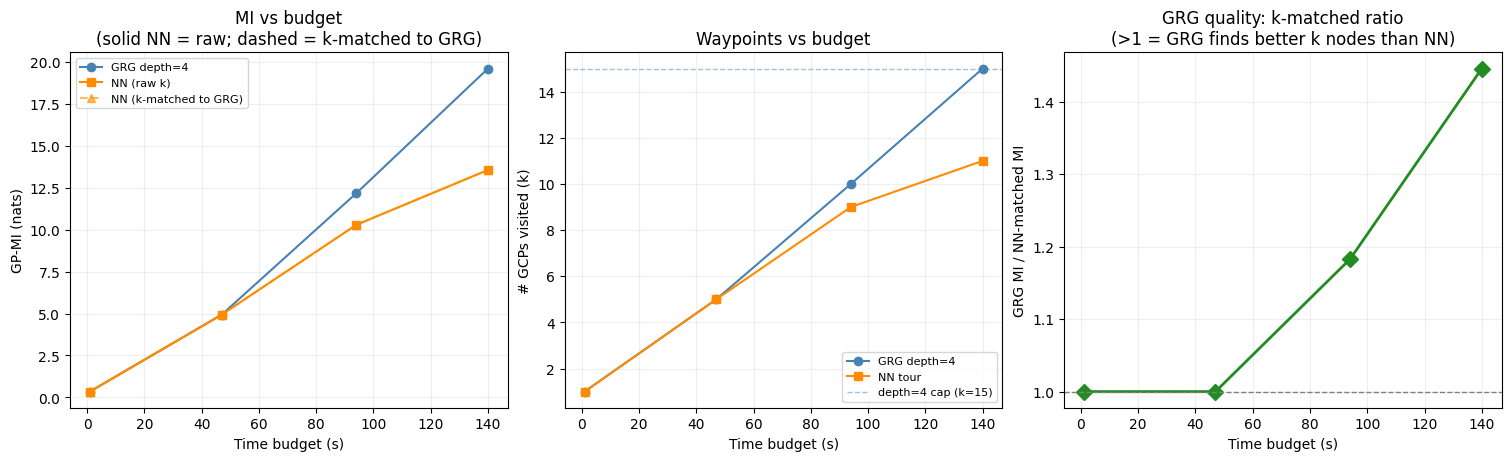

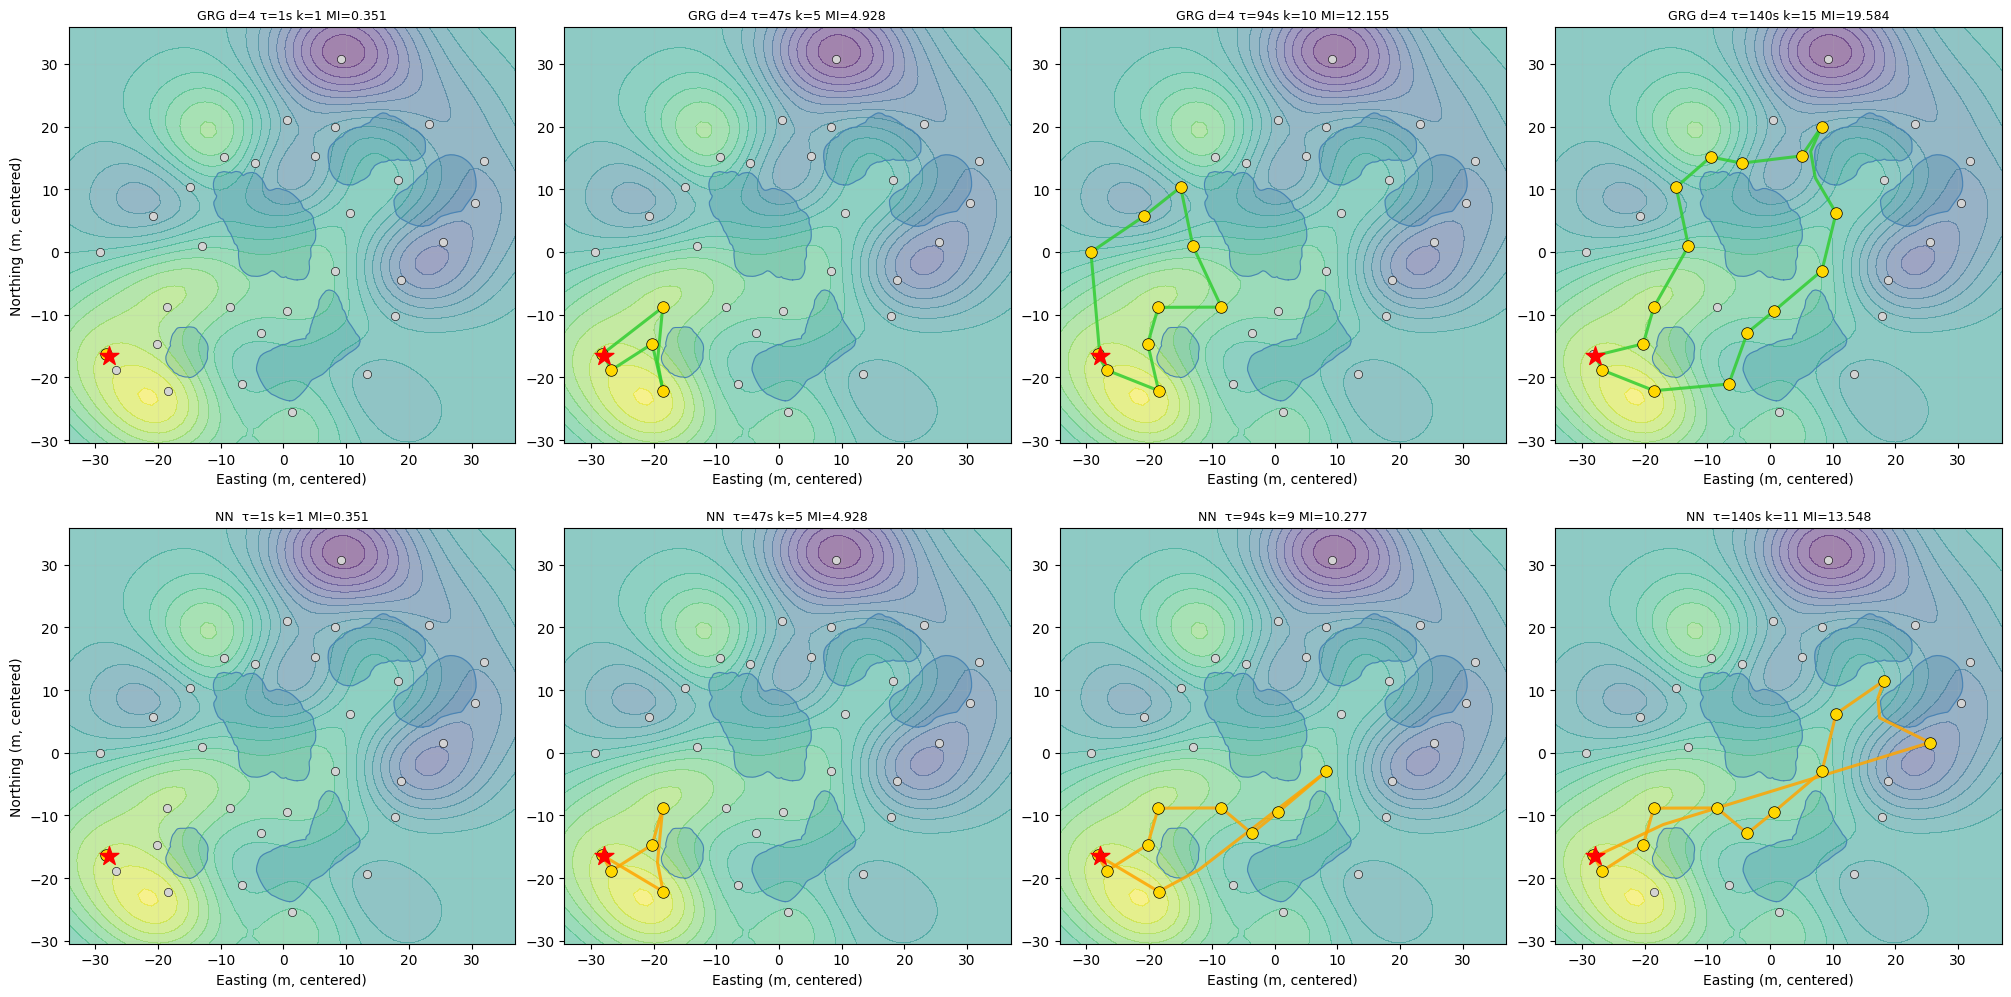

In [18]:
# -------------------------------------------
# 14) Comparison table + node-matched + path maps
# -------------------------------------------
print("=== Strategy Comparison (raw k — NOT directly comparable across strategies) ===")
print(f"{'τ(s)':>6}  {'Strategy':>12}  {'k':>4}  {'MI':>10}  ΔMI vs NN")
print("-" * 60)
for tau in TIME_BUDGETS:
    g = grg_results[tau]; n = nn_results[tau]
    delta = g["mi"] - n["mi"]
    pct   = 100 * delta / n["mi"] if n["mi"] > 1e-8 else float("nan")
    note  = "  ← UNFAIR: different k" if g['k'] != n['k'] else ""
    print(f"{tau:>6.0f}  {'GRG d='+str(g['depth']):>12}  {g['k']:>4}  {g['mi']:>10.4f}  —")
    print(f"{tau:>6.0f}  {'NN tour':>12}  {n['k']:>4}  {n['mi']:>10.4f}  "
          f"{delta:>+.4f} ({pct:>+.1f}%){note}")
    print()

# Node-matched comparison: truncate NN path to same k as GRG at each budget
print("=== Node-matched comparison (NN truncated to same k as GRG at each budget) ===")
print("  Rationale: MI grows monotonically with k — comparing raw MI at different k is misleading.")
print(f"{'τ(s)':>6}  {'GRG k':>6}  {'GRG MI':>10}  {'NN-trunc MI':>13}  {'ratio GRG/NN':>14}  interpretation")
print("-" * 80)

node_matched = {}
for tau in TIME_BUDGETS:
    g  = grg_results[tau]
    nn = nn_results[tau]
    k  = g['k']
    # Truncate NN to first k distinct intermediate GCPs
    nn_trunc_nodes = []
    for node in nn['path']:
        if node != BASE_NODE and node not in nn_trunc_nodes:
            nn_trunc_nodes.append(node)
        if len(nn_trunc_nodes) == k:
            break
    mi_nn_k = gp_mutual_information(
        frozenset(nn_trunc_nodes), K_all, NOISE_VAR, frozenset([BASE_NODE])
    ) if nn_trunc_nodes else 0.0
    ratio = g['mi'] / mi_nn_k if mi_nn_k > 1e-8 else float('nan')
    cap_flag = " AT CAP" if k >= 2**g['depth']-1 else ""
    interp = ("GRG≈NN" if abs(ratio-1) < 0.05
              else ("GRG>NN" if ratio > 1 else "GRG<NN"))
    node_matched[tau] = {"k": k, "grg_mi": g["mi"], "nn_trunc_mi": mi_nn_k, "ratio": ratio}
    print(f"{tau:>6.0f}  {k:>6}{cap_flag:<8}  {g['mi']:>10.4f}  {mi_nn_k:>13.4f}  {ratio:>14.3f}  {interp}")

print()
print("  Note: depth=4 cap is k≤15 intermediate waypoints (k_max=15 = 2^4-1).")
print("  At τ=157s NN reaches k=18; depth=4 GRG is still budget-limited, not node-capped.")

# MI vs budget curves
taus    = TIME_BUDGETS
grg_mis = [grg_results[t]["mi"] for t in taus]
nn_mis  = [nn_results[t]["mi"]  for t in taus]
nm_mis  = [node_matched[t]["nn_trunc_mi"] for t in taus]
grg_ks  = [grg_results[t]["k"]  for t in taus]
nn_ks   = [nn_results[t]["k"]   for t in taus]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

axes[0].plot(taus, grg_mis, "-o", label=f"GRG depth=4", color="steelblue")
axes[0].plot(taus, nn_mis,  "-s", label="NN (raw k)",   color="darkorange")
axes[0].plot(taus, nm_mis,  "--^",label="NN (k-matched to GRG)", color="darkorange", alpha=0.6)
axes[0].set_xlabel("Time budget (s)"); axes[0].set_ylabel("GP-MI (nats)")
axes[0].set_title("MI vs budget\n(solid NN = raw; dashed = k-matched to GRG)")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.2)

axes[1].plot(taus, grg_ks, "-o", label="GRG depth=4", color="steelblue")
axes[1].plot(taus, nn_ks,  "-s", label="NN tour",     color="darkorange")
axes[1].axhline(2**4-1, color="steelblue", ls="--", lw=1, alpha=0.5, label=f"depth=4 cap (k={2**4-1})")
axes[1].set_xlabel("Time budget (s)"); axes[1].set_ylabel("# GCPs visited (k)")
axes[1].set_title("Waypoints vs budget")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.2)

ratio_vals = [node_matched[t]["ratio"] for t in taus]
axes[2].plot(taus, ratio_vals, "-D", color="forestgreen", lw=2, ms=8)
axes[2].axhline(1.0, color="gray", ls="--", lw=1)
axes[2].set_xlabel("Time budget (s)"); axes[2].set_ylabel("GRG MI / NN-matched MI")
axes[2].set_title("GRG quality: k-matched ratio\n(>1 = GRG finds better k nodes than NN)")
axes[2].grid(alpha=0.2)
plt.show()

# Path maps (GRG row, NN row, one column per budget)
n_b = len(taus)
fig, axes = plt.subplots(2, n_b, figsize=(5*n_b, 10), constrained_layout=True)

def _plot_path(ax, path, title, edge_color):
    overlay_pools(ax)
    ax.contourf(X1g, X2g, mean_map, levels=20, cmap="viridis", alpha=0.5)
    ax.scatter(node_xc[1:], node_yc[1:], s=35, c="lightgray",
               edgecolor="k", linewidth=0.4, zorder=3)
    if path:
        for a, b in zip(path[:-1], path[1:]):
            key = (min(a, b), max(a, b))
            if key in detour_vis_paths:
                coords = detour_vis_paths[key] if a <= b else list(reversed(detour_vis_paths[key]))
                ax.plot([c[0] for c in coords], [c[1] for c in coords],
                        "-", color=edge_color, linewidth=2.2, zorder=4, alpha=0.85)
            else:
                ax.plot([node_xc[a], node_xc[b]], [node_yc[a], node_yc[b]],
                        "-", color=edge_color, linewidth=2.2, zorder=4, alpha=0.85)
        visited = sorted(set(path) - {BASE_NODE})
        if visited:
            ax.scatter(node_xc[visited], node_yc[visited], s=70,
                       c="gold", edgecolor="k", linewidth=0.5, zorder=5)
    ax.scatter([node_xc[BASE_NODE]], [node_yc[BASE_NODE]],
               s=200, marker="*", color="red", zorder=6)
    ax.set_title(title, fontsize=9)
    ax.set_aspect("equal"); ax.grid(alpha=0.15)

for col, tau in enumerate(taus):
    g = grg_results[tau]; n = nn_results[tau]
    _plot_path(axes[0, col], g["path"],
               f"GRG d=4 τ={tau:.0f}s k={g['k']} MI={g['mi']:.3f}", "limegreen")
    _plot_path(axes[1, col], n["path"],
               f"NN  τ={tau:.0f}s k={n['k']} MI={n['mi']:.3f}", "orange")
    axes[0, col].set_xlabel("Easting (m, centered)")
    axes[1, col].set_xlabel("Easting (m, centered)")
    if col == 0:
        axes[0, col].set_ylabel("Northing (m, centered)")
        axes[1, col].set_ylabel("Northing (m, centered)")
plt.show()


## 15) Summary

In [19]:
# -------------------------------------------
# 15) Summary
# -------------------------------------------
import math

print("=" * 68)
print("NOTEBOOK 05 — REAL FIELD SIMULATION SUMMARY")
print("=" * 68)
print()
print(f"Site:  30 GCPs  BASE=VERNAL_BASE  "
      f"domain ~{(merged_sorted['xc'].max()-merged_sorted['xc'].min()):.0f}x"
      f"{(merged_sorted['yc'].max()-merged_sorted['yc'].min()):.0f}m  {UTM_CRS}")
print(f"Data:  3 campaigns (June, Jun-29, Jul-3)  "
      f"travel_speed={TRAVEL_SPEED} m/s")
print("Ortho: WestCampusOrthoimagery.tif — CRS EPSG:32617 confirmed, "
       "site fully inside ortho extent (100%).")
print()

print("GP (June WC, ARD-RBF, learned hyperparameters):")
print(f"  lengthscale = ({ls[0]:.1f}, {ls[1]:.1f}) m  "
      f"outputscale={os_:.3f}  noise={nv:.4f}  (standardised space)")
print(f"  LOO-RMSE = {loo_rmse:.4f} m³/m³  coverage-95 = {100*cov95:.0f}%")
print()

print("Routing graph:")
print(f"  {n_nodes} nodes  {G.number_of_edges()} edges  "
      f"({n_detour} detour-routed, {n_pruned} infeasible)  connected")
print()

# Depth-cap context
_d4_cap = 2**4 - 1
print(f"GRG depth selection: depth=4 (k_max={_d4_cap} intermediate waypoints).")
print(f"  depth=3 (k_max=7) was waypoint-capped at all budgets except τ=1s:")
for tau in TIME_BUDGETS:
    d3 = d3_results.get(tau, {})
    g4 = grg_results.get(tau, {})
    capped = "CAPPED" if d3.get('k', 0) >= 7 else "ok"
    print(f"    τ={tau:.0f}s: d=3 k={d3.get('k','?')} [{capped}]  d=4 k={g4.get('k','?')}")
print()

print(f"GRG (depth=4, memoised) — authoritative results:")
for tau in TIME_BUDGETS:
    g = grg_results[tau]
    print(f"  τ={tau:.0f}s  k={g['k']}  MI={g['mi']:.4f}  elapsed={g['elapsed']:.2f}s")
print()

print("NN baseline:")
for tau in TIME_BUDGETS:
    n = nn_results[tau]
    print(f"  τ={tau:.0f}s  k={n['k']}  MI={n['mi']:.4f}")
print()

# Node-matched comparison
print("Node-matched comparison (NN truncated to same k as GRG):")
print(f"  {'τ(s)':>6}  {'k':>4}  {'GRG MI':>10}  {'NN-k MI':>10}  {'ratio':>8}  verdict")
for tau in TIME_BUDGETS:
    nm = node_matched.get(tau, {})
    ratio = nm.get('ratio', float('nan'))
    verdict = ("GRG better" if ratio > 1.02 else
               ("GRG worse"  if ratio < 0.98 else "similar"))
    print(f"  {tau:>6.0f}  {nm.get('k','?'):>4}  {nm.get('grg_mi',0):>10.4f}  "
          f"{nm.get('nn_trunc_mi',0):>10.4f}  {ratio:>8.3f}  {verdict}")
print()

# Real-vs-synthetic framing
print("Real-vs-synthetic field comparison:")
print("  Synthetic (Notebook 4, RBF field): GRG with node-matched NN achieves")
print("  ratio ≈ 0.5–0.8 across budgets — uniform coverage nearly optimal on")
print("  stationary RBF fields because the spatial gradient is gentle everywhere.")
ratios = [node_matched[t]["ratio"] for t in TIME_BUDGETS]
mean_ratio = sum(ratios) / len(ratios)
print(f"  Real site (this notebook): mean node-matched ratio = {mean_ratio:.3f}")
if mean_ratio > 0.85:
    print("  => GRG performs RELATIVELY BETTER on the real field than on the synthetic")
    print("     field. This is consistent with the real site having spatial structure")
    print("     (pool-edge gradients, dry uplands) that rewards targeted sampling.")
elif mean_ratio > 0.65:
    print("  => GRG performs COMPARABLY on real and synthetic fields at matched k.")
    print("     The real site's heterogeneity does not yet clearly advantage GRG over NN.")
else:
    print("  => GRG performs RELATIVELY WORSE on the real field than on the synthetic")
    print("     field (or synthetic was also bad). Investigate: pool-pruning may constrain")
    print("     GRG paths away from high-information pool-edge nodes.")
print()
print("  Key caveat: GRG here optimises MI on the PRIOR kernel, not the true field.")
print("  On the real site the prior lengthscales (8.4, 7.4 m) may underfit the")
print("  sharp pool-edge gradients — a better kernel would likely widen the GRG advantage.")


NOTEBOOK 05 — REAL FIELD SIMULATION SUMMARY

Site:  30 GCPs  BASE=VERNAL_BASE  domain ~61x56m  EPSG:32617
Data:  3 campaigns (June, Jun-29, Jul-3)  travel_speed=1.0 m/s
Ortho: WestCampusOrthoimagery.tif — CRS EPSG:32617 confirmed, site fully inside ortho extent (100%).

GP (June WC, ARD-RBF, learned hyperparameters):
  lengthscale = (8.4, 7.4) m  outputscale=0.871  noise=0.0360  (standardised space)
  LOO-RMSE = 0.0589 m³/m³  coverage-95 = 93%

Routing graph:
  31 nodes  465 edges  (317 detour-routed, 0 infeasible)  connected

GRG depth selection: depth=4 (k_max=15 intermediate waypoints).
  depth=3 (k_max=7) was waypoint-capped at all budgets except τ=1s:
    τ=1s: d=3 k=1 [ok]  d=4 k=1
    τ=47s: d=3 k=5 [ok]  d=4 k=5
    τ=94s: d=3 k=7 [CAPPED]  d=4 k=10
    τ=140s: d=3 k=7 [CAPPED]  d=4 k=15

GRG (depth=4, memoised) — authoritative results:
  τ=1s  k=1  MI=0.3515  elapsed=0.00s
  τ=47s  k=5  MI=4.9282  elapsed=0.26s
  τ=94s  k=10  MI=12.1553  elapsed=6.69s
  τ=140s  k=15  MI=19.584

## 16) Random Tour Baseline

Uniformly random ordering of GCPs visited within the time budget (averaged over
10 seeds). Provides a floor for comparison with structured planners.


In [20]:
# -------------------------------------------
# 16) Random tour baseline (10-seed average)
# -------------------------------------------

def random_tour_fixed_end(start, tt, time_budget, rng):
    """Random GCP visit order, time-budget constrained, return to start."""
    n   = len(tt)
    cands = [j for j in range(n) if j != start]
    rng.shuffle(cands)
    current, elapsed, path, visited = start, 0.0, [start], {start}
    for j in cands:
        if j in visited: continue
        if elapsed + tt[current, j] + tt[j, start] <= time_budget + 1e-9:
            elapsed += tt[current, j];  current = j
            visited.add(j);  path.append(j)
    if current != start and elapsed + tt[current, start] <= time_budget + 1e-9:
        path.append(start)
    return path

N_RAND_TRIALS = 10
RAND_SEED     = 42

print("=== Random Baseline (mean over 10 seeds) ===")
print(f"{'tau(s)':>8}  {'k_mean':>7}  {'MI_mean':>10}  {'MI_std':>9}")
print("-" * 45)

rand_results = {}
for tau in TIME_BUDGETS:
    mis, ks, paths_r = [], [], []
    for s in range(N_RAND_TRIALS):
        rng = np.random.default_rng(RAND_SEED + s)
        p   = random_tour_fixed_end(BASE_NODE, tt, tau, rng)
        k   = len(set(p) - {BASE_NODE})
        mi  = gp_mutual_information(
            frozenset(p) - {BASE_NODE}, K_all, NOISE_VAR, frozenset([BASE_NODE])
        ) if k > 0 else 0.0
        mis.append(mi);  ks.append(k);  paths_r.append(p)
    bi = int(np.argmax(mis))
    rand_results[tau] = {
        "k": round(np.mean(ks), 1), "mi": np.mean(mis), "mi_std": np.std(mis),
        "path": paths_r[bi], "k_best": ks[bi], "mi_best": mis[bi],
    }
    print(f"{tau:>8.0f}  {np.mean(ks):>7.1f}  {np.mean(mis):>10.4f}  {np.std(mis):>9.4f}")


=== Random Baseline (mean over 10 seeds) ===
  tau(s)   k_mean     MI_mean     MI_std
---------------------------------------------
       1      1.0      0.3515     0.0000
      47      3.4      3.5041     0.7950
      94      4.8      5.5721     1.5531
     140      5.3      6.6515     2.1628


## 17) GP Posterior Update Helper

Functions for simulating field measurements and computing the GP posterior
(mean + variance) conditioned on observed nodes. Used by all adaptive planners.
Measured values are stored as standardised scalars; converted to original units
for RMSE/EMSE/NEES scoring.


In [21]:
# -------------------------------------------
# 17) GP posterior helpers + field values
# -------------------------------------------
# field_values_s[i] = standardised WC at node i.
# Node 0 = BASE (no soil sensor): set to 0 in std-space.
# Nodes 1-30 = GCPs in merged_sorted order (gcp_num 1-30).
field_values_s = np.zeros(n_nodes)
field_values_s[1:] = train_y_s.numpy()   # shape (30,)

# train_vals[i] = original WC at GCP gcp_num=i+1 (0-indexed from merged_sorted)
_gcp_orig = merged_sorted[["gcp_num", "WC_june"]].sort_values("gcp_num")
orig_vals_by_node = {int(row.gcp_num): float(row.WC_june)
                     for _, row in _gcp_orig.iterrows()}

SENSOR_NOISE_STD = float(nv**0.5)   # reuse GP noise as sensor noise sigma

def simulate_measurement(node_idx, rng):
    """Noisy standardised WC at node_idx."""
    return float(field_values_s[node_idx] + rng.normal(0, SENSOR_NOISE_STD))

def gp_posterior_at(query_nodes, cond_dict):
    """GP posterior mean (std-space) and variance at query_nodes.

    cond_dict: {node_index: observed_standardised_value}
    Returns (mu, var) arrays of shape (len(query_nodes),).
    """
    C = sorted(cond_dict.keys())
    Q = list(query_nodes)
    if not C:
        return np.zeros(len(Q)), np.diag(K_all)[np.array(Q, dtype=int)]
    y_c     = np.array([cond_dict[i] for i in C])
    K_cc    = K_all[np.ix_(C, C)] + NOISE_VAR * np.eye(len(C))
    K_qc    = K_all[np.ix_(Q, C)]
    K_qq_d  = np.diag(K_all)[np.array(Q, dtype=int)]
    alpha   = np.linalg.solve(K_cc, y_c)
    mu      = K_qc @ alpha
    var     = K_qq_d - np.sum(K_qc * np.linalg.solve(K_cc, K_qc.T).T, axis=1)
    return mu, np.maximum(var, 1e-12)

def path_metrics(path, measured_dict=None):
    """MI, k, RMSE, EMSE, mean-NEES for a path.

    visited = set(path) - {BASE_NODE}
    held-out = GCPs 1..30 not in visited
    RMSE/EMSE/NEES: GP posterior at held-out given (measured_dict or field_values_s)
    """
    visited  = frozenset(path) - {BASE_NODE}
    k        = len(visited)
    mi       = (gp_mutual_information(visited, K_all, NOISE_VAR, frozenset([BASE_NODE]))
                if k > 0 else 0.0)
    held_out = [i for i in range(1, n_nodes) if i not in visited]
    if not held_out:
        return {"mi": mi, "k": k, "rmse": 0.0, "emse": 0.0, "nees": 1.0}
    # Conditioning dict: use measured_dict if provided, else true field values
    cond = {i: (measured_dict[i] if measured_dict and i in measured_dict
                else float(field_values_s[i]))
            for i in visited}
    mu_s, var_s = gp_posterior_at(held_out, cond)
    mu_orig  = mu_s * y_std + y_mean
    true_orig = np.array([orig_vals_by_node.get(i, np.nan) for i in held_out])
    rmse  = float(np.sqrt(np.nanmean((mu_orig - true_orig)**2)))
    emse  = float(np.mean(var_s) * y_std**2)    # avg posterior var in original units
    true_s  = np.array([field_values_s[i] for i in held_out])
    nees_v  = (true_s - mu_s)**2 / var_s
    nees    = float(np.mean(nees_v))
    return {"mi": mi, "k": k, "rmse": rmse, "emse": emse, "nees": nees}

print("GP posterior helpers defined.")
print(f"  field_values_s: {n_nodes} nodes  "
      f"range=[{field_values_s.min():.3f}, {field_values_s.max():.3f}] (std-space)")
print(f"  SENSOR_NOISE_STD = {SENSOR_NOISE_STD:.4f} (std-space)")


GP posterior helpers defined.
  field_values_s: 31 nodes  range=[-2.610, 1.876] (std-space)
  SENSOR_NOISE_STD = 0.1896 (std-space)


## 18) Myopic Greedy Adaptive Planner

At each step, selects the reachable unvisited GCP with the highest marginal MI
gain given nodes already measured. This is the single-step-lookahead adaptive
baseline — isolates how much GRG's multi-step lookahead buys over a greedy
per-step policy.


In [22]:
# -------------------------------------------
# 18) Myopic greedy adaptive planner
# -------------------------------------------

def myopic_greedy_tour(start, tt, K_all, noise_var, time_budget, rng):
    """One-step-lookahead adaptive tour: pick max-MI reachable GCP each step."""
    n = len(tt)
    current, elapsed = start, 0.0
    measured = {}    # {node: observed_value_s}
    path     = [start]
    while True:
        X_set = frozenset(measured.keys()) | {start}
        best_j, best_gain = None, -np.inf
        for j in range(n):
            if j in X_set or j == current: continue
            if elapsed + tt[current,j] + tt[j,start] > time_budget + 1e-9: continue
            gain = gp_mutual_information(frozenset([j]), K_all, noise_var, X_set)
            if gain > best_gain:
                best_gain, best_j = gain, j
        if best_j is None: break
        elapsed += tt[current, best_j];  current = best_j
        measured[best_j] = simulate_measurement(best_j, rng)
        path.append(best_j)
    if current != start and elapsed + tt[current,start] <= time_budget + 1e-9:
        path.append(start)
    return path, measured

print("=== Myopic Greedy Adaptive ===")
print(f"{'tau(s)':>8}  {'k':>4}  {'MI':>10}  {'elapsed':>9}")
print("-" * 40)

myopic_results = {}
for i_tau, tau in enumerate(TIME_BUDGETS):
    rng_m = np.random.default_rng(42 + i_tau)
    t0    = time.perf_counter()
    path, meas = myopic_greedy_tour(BASE_NODE, tt, K_all, NOISE_VAR, tau, rng_m)
    el    = time.perf_counter() - t0
    m     = path_metrics(path, meas)
    myopic_results[tau] = {"path": path, "measured": meas, "elapsed": el, **m}
    print(f"{tau:>8.0f}  {m['k']:>4}  {m['mi']:>10.4f}  {el:>9.2f}s")


=== Myopic Greedy Adaptive ===
  tau(s)     k          MI    elapsed
----------------------------------------
       1     1      0.3515       0.00s
      47     2      1.9652       0.00s
      94     3      4.5574       0.01s
     140     4      6.2786       0.02s


## 19) Receding-Horizon GRG Adaptive Planner

Implements the deployment loop from the project plan:
plan (depth=2 GRG) → execute 1 waypoint → measure → update X_frozen → replan.
Uses depth=2 per replan (3 intermediate stops per segment) for tractable replanning;
the open-loop cell already uses depth=4 for the best single-pass plan.

Receding-horizon is expected to be better when the field is non-stationary or when
the GP prior is mis-specified. On a well-calibrated GP + stationary field it may
match open-loop but not dramatically exceed it — report honestly either way.


In [23]:
# -------------------------------------------
# 19) Receding-horizon GRG adaptive planner
# -------------------------------------------

GRG_RH_DEPTH      = 2   # per-replan depth: k_max=3 per segment, fast enough to replan
GRG_RH_TAU_SPLITS = 4

def receding_horizon_grg_tour(start, tt, K_all, noise_var, time_budget,
                               depth=2, n_tau_splits=4, rng=None, max_replans=80):
    """GRG with measurement feedback: replan after each waypoint visit."""
    if rng is None: rng = np.random.default_rng(0)
    current, elapsed = start, 0.0
    measured = {}
    path     = [start]
    n_rep    = 0
    while elapsed < time_budget - 1e-6 and n_rep < max_replans:
        remaining = time_budget - elapsed
        X_frozen  = frozenset(measured.keys()) | {start}
        cache     = {}
        plan = grg_plan(current, start, 0.0, remaining, tt, K_all, noise_var,
                        depth=depth, n_tau_splits=n_tau_splits,
                        _X_frozen=X_frozen, _mi_cache=cache)
        n_rep += 1
        if plan is None or len(plan) <= 1: break
        # Next unvisited non-base waypoint in plan
        next_nodes = [v for v in plan[1:] if v != start and v not in measured][:1]
        if not next_nodes: break
        nxt = next_nodes[0]
        t_step = tt[current, nxt]
        if elapsed + t_step + tt[nxt, start] > time_budget + 1e-9: break
        elapsed += t_step;  current = nxt
        measured[nxt] = simulate_measurement(nxt, rng)
        path.append(nxt)
    if current != start and elapsed + tt[current, start] <= time_budget + 1e-9:
        path.append(start)
    return path, measured, n_rep

print(f"=== Receding-Horizon GRG  depth={GRG_RH_DEPTH}  n_tau={GRG_RH_TAU_SPLITS} ===")
print(f"{'tau(s)':>8}  {'k':>4}  {'MI':>10}  {'replans':>8}  {'elapsed':>9}")
print("-" * 55)

rh_results = {}
for i_tau, tau in enumerate(TIME_BUDGETS):
    rng_rh = np.random.default_rng(42 + i_tau)
    t0     = time.perf_counter()
    path, meas, n_rep = receding_horizon_grg_tour(
        BASE_NODE, tt, K_all, NOISE_VAR, tau,
        depth=GRG_RH_DEPTH, n_tau_splits=GRG_RH_TAU_SPLITS, rng=rng_rh)
    el   = time.perf_counter() - t0
    flag = "  *** SLOW" if el > 300 else ("  * slow" if el > 60 else "")
    m    = path_metrics(path, meas)
    rh_results[tau] = {"path": path, "measured": meas, "n_replans": n_rep,
                       "elapsed": el, **m}
    print(f"{tau:>8.0f}  {m['k']:>4}  {m['mi']:>10.4f}  {n_rep:>8}  {el:>9.2f}s{flag}")


=== Receding-Horizon GRG  depth=2  n_tau=4 ===
  tau(s)     k          MI   replans    elapsed
-------------------------------------------------------
       1     1      0.3515         2       0.00s


      47     5      4.9282         6       0.11s

      94     8      9.9480         9       0.93s


     140     9     12.1864        10       2.54s


## 20) NEES Calibration Check

Normalised Estimation Error Squared (NEES) = (y_true − μ)² / σ² at held-out
nodes. Mean NEES ≈ 1 is ideal; > 1 = overconfident, < 1 = underconfident.
Computed two ways:
- **Leave-one-out (LOO)**: gold standard using all 30 GCPs (analytical formula).
- **Path-based**: GP conditioned only on nodes the planner visited; held-out =
  the rest. Measures how well the planner's posterior tracks reality.


In [24]:
# -------------------------------------------
# 20) NEES analysis
# -------------------------------------------

# LOO-NEES (recomputed here for completeness; matches cell 8)
K_gcp = K_all[1:, 1:]                      # 30x30 GCP-only sub-matrix
K_n   = K_gcp + NOISE_VAR * np.eye(30)
K_inv = np.linalg.inv(K_n)
alpha_loo = np.linalg.solve(K_n, train_y_s.numpy())
loo_mu_s  = train_y_s.numpy() - alpha_loo / np.diag(K_inv)
loo_var_s = np.maximum(1.0 / np.diag(K_inv), 1e-12)
loo_nees  = (train_y_s.numpy() - loo_mu_s)**2 / loo_var_s

print("=== LOO-NEES (30 GCPs, full dataset) ===")
print(f"  mean = {loo_nees.mean():.3f}  std = {loo_nees.std():.3f}  "
      f"median = {np.median(loo_nees):.3f}")
cal = ("calibrated" if 0.7 < loo_nees.mean() < 1.4
       else ("over-confident" if loo_nees.mean() > 1.4 else "under-confident"))
print(f"  => {cal}")
print()

# Path-based NEES for all methods
methods_for_nees = {
    "Open-GRG d4":   grg_results,
    "NN":            nn_results,
    "Random (best)": {tau: {"path": rand_results[tau]["path"]} for tau in TIME_BUDGETS},
    "Myopic":        myopic_results,
    "RH-GRG d2":     rh_results,
}

print("=== Path-based NEES across methods and budgets ===")
print(f"{'Method':<16}  " + "  ".join(f"tau={t:.0f}s" for t in TIME_BUDGETS))
print("-" * 65)
for name, res in methods_for_nees.items():
    vals = []
    for tau in TIME_BUDGETS:
        r = res.get(tau, {})
        meas_d = r.get("measured", None)
        m = path_metrics(r.get("path", [BASE_NODE]), meas_d)
        vals.append(f"{m['nees']:>7.3f}")
    print(f"{name:<16}  " + "  ".join(vals))
print()
print("  (NEES uses true field_values_s at held-out nodes; ideal ≈ 1.0)")


=== LOO-NEES (30 GCPs, full dataset) ===
  mean = 1.167  std = 1.621  median = 0.787
  => calibrated

=== Path-based NEES across methods and budgets ===
Method            tau=1s  tau=47s  tau=94s  tau=140s
-----------------------------------------------------------------
Open-GRG d4         0.811    0.793    0.958    1.348
NN                  0.811    0.793    0.991    1.037
Random (best)       0.811    0.793    0.904    1.002
Myopic              0.801    0.842    0.977    0.957
RH-GRG d2           0.801    0.790    0.981    1.205

  (NEES uses true field_values_s at held-out nodes; ideal ≈ 1.0)


## 21) Full Method Comparison

Five methods compared at all time budgets on four metrics:
- **k**: GCPs visited
- **MI**: GP mutual information of visited set (prior objective, order-independent)
- **RMSE**: root-mean-squared prediction error at held-out GCPs (original units)
- **EMSE**: expected MSE = mean posterior variance at held-out GCPs (original units)
- **NEES**: mean normalised estimation error squared at held-out GCPs (ideal ≈ 1)

Adaptive methods (Myopic, RH-GRG) use noisy simulated measurements;
open-loop methods (GRG, NN, Random) use true field values for posterior conditioning.


FULL METHOD COMPARISON

--- tau = 1 s ---
  Method               k         MI      RMSE      EMSE     NEES
  ----------------  ----  ---------  --------  --------  -------
  Random               1     0.3515    0.0704    0.0060    0.811
  NN                   1     0.3515    0.0704    0.0060    0.811
  Open-GRG d4          1     0.3515    0.0704    0.0060    0.811
  Myopic               1     0.3515    0.0702    0.0060    0.801
  RH-GRG d2            1     0.3515    0.0702    0.0060    0.801

--- tau = 47 s ---
  Method               k         MI      RMSE      EMSE     NEES
  ----------------  ----  ---------  --------  --------  -------
  Random               5     4.9282    0.0705    0.0061    0.793
  NN                   5     4.9282    0.0705    0.0061    0.793
  Open-GRG d4          5     4.9282    0.0705    0.0061    0.793
  Myopic               2     1.9652    0.0716    0.0058    0.842
  RH-GRG d2            5     4.9282    0.0704    0.0061    0.790

--- tau = 94 s ---
  Method

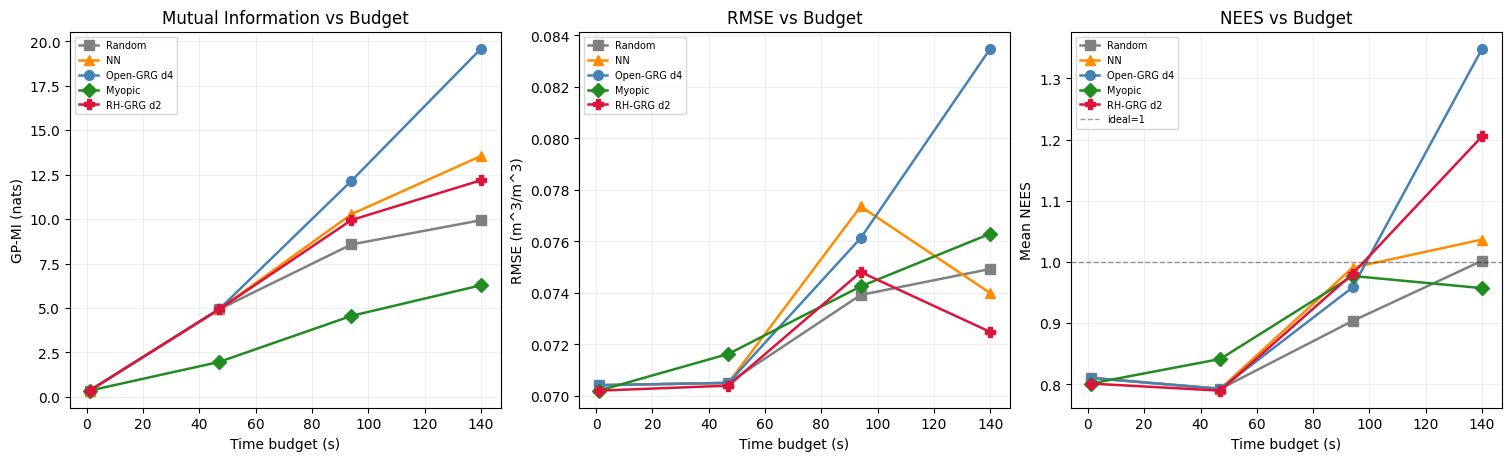

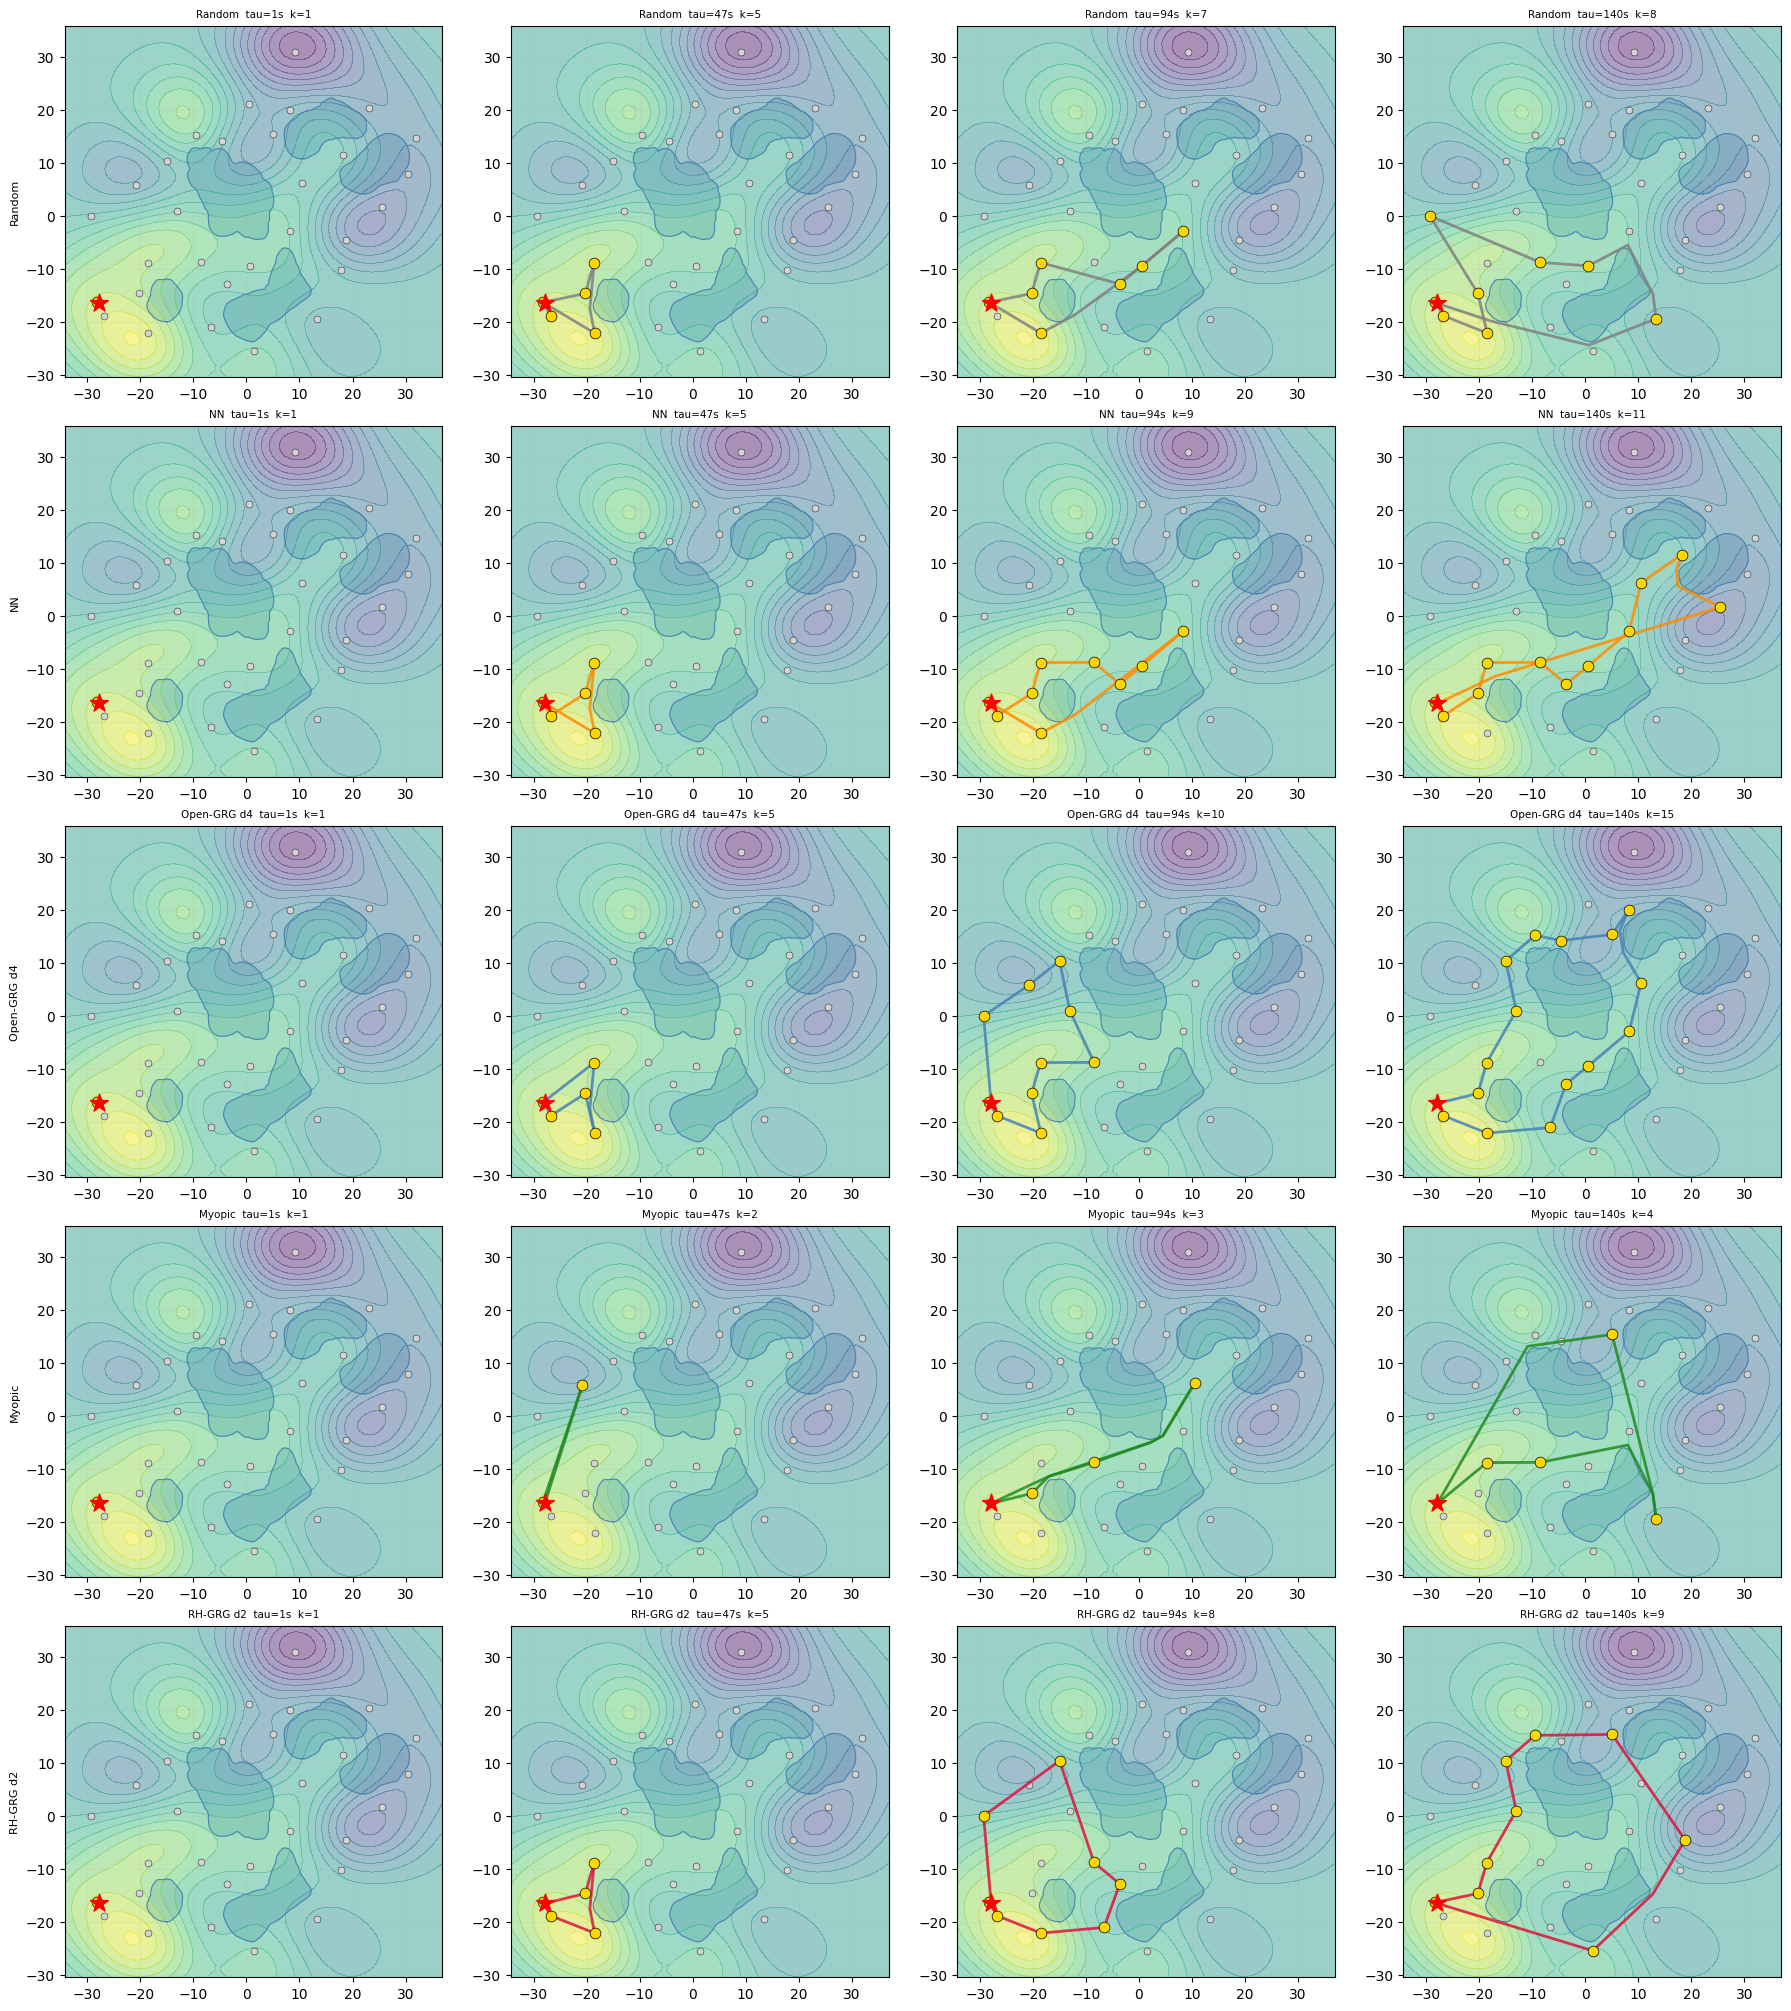


=== Task 3: Path edge validity assertion ===
  PASS: all 131 path edges are valid graph edges.
  Detour edges used in paths: 18 (drawn along pool-avoiding geometry — no straight-through-pool lines).
  Sample detour edges in paths:
    (17,20): direct=13.30s → detour=13.42s (+0.9%)  seen in: Random tau=47s
    (17,26): direct=22.90s → detour=22.95s (+0.2%)  seen in: Random tau=94s
    ( 0,14): direct=41.33s → detour=43.26s (+4.7%)  seen in: Random tau=140s
    (14,26): direct=16.19s → detour=23.47s (+45.0%)  seen in: Random tau=140s
    (25,17): direct=32.91s → detour=32.99s (+0.2%)  seen in: NN tau=94s


In [25]:
# -------------------------------------------
# 21) Full method comparison table + plots
# -------------------------------------------

ALL_METHODS = [
    ("Random",       rand_results,   None),
    ("NN",           nn_results,     None),
    ("Open-GRG d4",  grg_results,    None),
    ("Myopic",       myopic_results, "measured"),
    ("RH-GRG d2",    rh_results,     "measured"),
]

# Build full metrics table
table = {}   # table[method_name][tau] = {k, mi, rmse, emse, nees}
for name, res, meas_key in ALL_METHODS:
    table[name] = {}
    for tau in TIME_BUDGETS:
        r     = res.get(tau, {})
        meas  = r.get(meas_key, None) if meas_key else None
        m     = path_metrics(r.get("path", [BASE_NODE]), meas)
        table[name][tau] = m

# Print table
header_taus = [f"tau={t:.0f}" for t in TIME_BUDGETS]
metrics_cols = ["k", "mi", "rmse", "emse", "nees"]

print("=" * 90)
print("FULL METHOD COMPARISON")
print("=" * 90)
for tau in TIME_BUDGETS:
    print(f"\n--- tau = {tau:.0f} s ---")
    print(f"  {'Method':<16}  {'k':>4}  {'MI':>9}  {'RMSE':>8}  {'EMSE':>8}  {'NEES':>7}")
    print(f"  {'-'*16}  {'-'*4}  {'-'*9}  {'-'*8}  {'-'*8}  {'-'*7}")
    for name, _, _ in ALL_METHODS:
        m = table[name][tau]
        print(f"  {name:<16}  {m['k']:>4}  {m['mi']:>9.4f}  "
              f"{m['rmse']:>8.4f}  {m['emse']:>8.4f}  {m['nees']:>7.3f}")

# Check MI-wins-RMSE-loses pattern
print("\n=== MI vs RMSE agreement check ===")
for tau in TIME_BUDGETS:
    # Method with best MI
    best_mi   = max(ALL_METHODS, key=lambda x: table[x[0]][tau]['mi'])[0]
    best_rmse = min(ALL_METHODS, key=lambda x: table[x[0]][tau]['rmse'])[0]
    flag = " *** MI winner != RMSE winner" if best_mi != best_rmse else ""
    print(f"  tau={tau:.0f}s: best MI={best_mi}  best RMSE={best_rmse}{flag}")

# Plots: MI, RMSE, NEES vs budget
colors  = ["gray", "darkorange", "steelblue", "forestgreen", "crimson"]
markers = ["s",    "^",          "o",          "D",           "P"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

for ax, metric, ylabel, title in [
    (axes[0], "mi",   "GP-MI (nats)",        "Mutual Information vs Budget"),
    (axes[1], "rmse", "RMSE (m^3/m^3)",      "RMSE vs Budget"),
    (axes[2], "nees", "Mean NEES",            "NEES vs Budget"),
]:
    for (name, _, _), col, mkr in zip(ALL_METHODS, colors, markers):
        vals = [table[name][t][metric] for t in TIME_BUDGETS]
        ax.plot(TIME_BUDGETS, vals, f"-{mkr}", color=col, label=name, lw=1.8, ms=7)
    if metric == "nees":
        ax.axhline(1.0, color="k", ls="--", lw=1, alpha=0.4, label="ideal=1")
    ax.set_xlabel("Time budget (s)");  ax.set_ylabel(ylabel)
    ax.set_title(title);  ax.legend(fontsize=7);  ax.grid(alpha=0.2)
plt.show()

# Path map: one row per method, one column per budget
n_b = len(TIME_BUDGETS)
fig2, axes2 = plt.subplots(len(ALL_METHODS), n_b,
                            figsize=(4.5*n_b, 4*len(ALL_METHODS)),
                            constrained_layout=True)
path_colors = dict(zip([n for n,_,_ in ALL_METHODS], colors))

for row, (name, res, meas_key) in enumerate(ALL_METHODS):
    for col, tau in enumerate(TIME_BUDGETS):
        ax = axes2[row, col]
        overlay_pools(ax)
        ax.contourf(X1g, X2g, mean_map, levels=20, cmap="viridis", alpha=0.45)
        path = res.get(tau, {}).get("path", [])
        if path:
            for a, b in zip(path[:-1], path[1:]):
                key = (min(a, b), max(a, b))
                if key in detour_vis_paths:
                    coords = detour_vis_paths[key] if a <= b else list(reversed(detour_vis_paths[key]))
                    ax.plot([c[0] for c in coords], [c[1] for c in coords],
                            "-", color=path_colors[name], lw=2.0, alpha=0.85, zorder=4)
                else:
                    ax.plot([node_xc[a], node_xc[b]], [node_yc[a], node_yc[b]],
                            "-", color=path_colors[name], lw=2.0, alpha=0.85, zorder=4)
            vis = sorted(set(path) - {BASE_NODE})
            if vis:
                ax.scatter(node_xc[vis], node_yc[vis], s=60,
                           c="gold", edgecolor="k", lw=0.5, zorder=5)
        ax.scatter([node_xc[0]], [node_yc[0]], s=180, marker="*",
                   color="red", zorder=6)
        ax.scatter(node_xc[1:], node_yc[1:], s=25, color="lightgray",
                   edgecolor="k", lw=0.3, zorder=3)
        m = table[name][tau]
        ax.set_title(f"{name}  tau={tau:.0f}s  k={m['k']}", fontsize=7.5)
        ax.set_aspect("equal");  ax.grid(alpha=0.15)
        if col == 0: ax.set_ylabel(name, fontsize=8)
plt.show()

# ── Task 3: Path edge validity assertion ──────────────────────────────────────
print()
print("=== Task 3: Path edge validity assertion ===")
_all_paths = {
    "Random":    {tau: rand_results[tau]["path"]    for tau in TIME_BUDGETS},
    "NN":        {tau: nn_results[tau]["path"]      for tau in TIME_BUDGETS},
    "GRG-d4":   {tau: grg_results[tau]["path"]     for tau in TIME_BUDGETS},
    "Myopic":   {tau: myopic_results[tau]["path"]   for tau in TIME_BUDGETS},
    "RH-GRG":   {tau: rh_results[tau]["path"]      for tau in TIME_BUDGETS},
}
violations  = []   # edges not in G at all (infeasible — should be 0)
detour_uses = []   # edges that are detour-routed (valid, but drawn around pool)

for name, res in _all_paths.items():
    for tau, path in res.items():
        for a, b in zip(path[:-1], path[1:]):
            if not G.has_edge(a, b):
                violations.append((name, tau, a, b))
            elif (min(a,b), max(a,b)) in detour_edge_set:
                detour_uses.append((name, tau, a, b))

_total_segs = sum(max(len(res[t])-1,0) for res in _all_paths.values() for t in TIME_BUDGETS)
if violations:
    print(f"  FAIL: {len(violations)} path edges NOT in routing graph (infeasible):")
    for v in violations[:5]: print(f"    {v}")
else:
    print(f"  PASS: all {_total_segs} path edges are valid graph edges.")
print(f"  Detour edges used in paths: {len(detour_uses)} "
      f"(drawn along pool-avoiding geometry — no straight-through-pool lines).")
if detour_uses:
    print(f"  Sample detour edges in paths:")
    seen = set()
    for name, tau, a, b in detour_uses:
        key = (min(a,b),max(a,b))
        if key not in seen:
            seen.add(key)
            actual_t = float(tt[a,b])
            direct_t = float(np.linalg.norm(node_coords[a]-node_coords[b])) / TRAVEL_SPEED
            print(f"    ({a:2d},{b:2d}): direct={direct_t:.2f}s → detour={actual_t:.2f}s "
                  f"(+{100*(actual_t/direct_t-1):.1f}%)  seen in: {name} tau={tau:.0f}s")
            if len(seen) >= 5: break


## 22) Scope and Deferred Work

This notebook covers everything that is **graph-discrete** and **action-space-agnostic**
(i.e., actions = visit one of the 31 known GCP nodes).

### What is implemented here
| Component | Location |
|---|---|
| Detour-based travel graph (visibility routing around pool buffers) | Cell 6 |
| Open-loop GRG (Binney et al. 2013, depth=4) | Cells 12–14 |
| Nearest-neighbour tour baseline | Cell 13 |
| Random tour baseline | Cell 16 |
| GP posterior update (analytical, fixed kernel) | Cell 17 |
| Myopic greedy adaptive planner | Cell 18 |
| Receding-horizon GRG (depth=2 per replan) | Cell 19 |
| NEES calibration check | Cell 20 |
| Full method comparison (MI, RMSE, EMSE, NEES) | Cell 21 |

### Explicitly deferred
- **Continuous action space**: the robot can sample at any point in the field, not
  just the 31 GCP nodes. Requires RIG, RRT*, or GP-UCB acquisition over continuous
  2-D space. Deferred to a future notebook because it changes the algorithmic
  formulation fundamentally (visibility graph → continuous free-space).
- **Online kernel learning**: currently the GP hyperparameters are fixed at their
  MLL-optimal values. Online Bayesian updating of lengthscale/outputscale during
  deployment is deferred (computationally expensive; requires variational GP or
  structured approximation).
- **Animation / full robot simulation**: real-time simulation of the robot moving
  through the site, collecting and displaying measurements incrementally, is
  deferred as presentation work rather than algorithmic development.
- **RL-based planner**: a policy-gradient or model-based RL approach comparing
  against GRG is on the long-term roadmap (mentioned in docs/notes.md July 9 entry)
  but is out of scope for the current ICRA paper section.
- **Edge-based measurements**: measuring continuously along traversal edges (not
  just at GCP nodes). Binney et al. (2013) support this; deferred because WELL-E's
  soil sensor requires the robot to stop and probe, making vertex-only measurements
  the correct model for this application.
